In [29]:
import sys, importlib
from pathlib import Path
import pandas as pd

sys.path.insert(0, str(Path("..").resolve()))

CACHE = Path("../data/interim/sheets_raw")
key = "ID_UC_G0"
SKIP = ("Description", "Index")
sheets = {p.stem: pd.read_parquet(p) for p in CACHE.glob("*.parquet")}
print(len(sheets), "листов загружено")

txt = (Path("..") / "src" / "cleaning.py").read_text(encoding="utf-8")
print("cleaning.py:", len(txt.splitlines()), "строк | build_clean есть:", "def build_clean" in txt)

17 листов загружено
cleaning.py: 352 строк | build_clean есть: True


In [30]:
import src.cleaning
importlib.reload(src.cleaning)
from src.cleaning import clean_sheet, build_clean

final, stats = {}, []
for n, d in sheets.items():
    if n in SKIP:
        continue
    final[n], st = clean_sheet(d, key)
    stats.append({"лист": n, **st})
print(len(final), "листов очищено")

15 листов очищено


In [31]:
import sys
from pathlib import Path
import pandas as pd

# чтобы работал import src.*
sys.path.insert(0, str(Path("..").resolve()))

# автоподхват правок в src/*.py без перезапуска ядра
%load_ext autoreload
%autoreload 2

RAW = Path("../data/raw/GHS_UCDB_REGION_LATIN_AMERICA_AND_THE_CARIBBEAN_R2024A.xlsx")
CACHE = Path("../data/interim/sheets_raw")
key = "ID_UC_G0"

if CACHE.exists() and any(CACHE.glob("*.parquet")):
    sheets = {p.stem: pd.read_parquet(p) for p in CACHE.glob("*.parquet")}
else:
    sheets = pd.read_excel(RAW, sheet_name=None)
    CACHE.mkdir(parents=True, exist_ok=True)
    for name, d in sheets.items():
        if name in ("Index", "Description"):
            d = d.astype("string")
        d.to_parquet(CACHE / f"{name}.parquet")

print(len(sheets), "листов загружено")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
17 листов загружено


In [32]:
clean_final, rep = build_clean(final, key, sheets["Index"])
print(clean_final.shape, "| строк с долей вне 0-100:", rep["строк_с_долей_вне_0_100"],
      "| выбросы:", rep["выбросы_log_iqr"])

(1089, 2619) | строк с долей вне 0-100: 48 | выбросы: {'GC_POP_TOT_2025': 49, 'GC_UCA_KM2_2025': 44}


In [33]:
import pandas as pd
xlsx = Path("../data/raw/GHS_UCDB_REGION_LATIN_AMERICA_AND_THE_CARIBBEAN_R2024A.xlsx")
print(pd.ExcelFile(xlsx).sheet_names)

['Description', 'Index', 'GENERAL_CHARACTERISTICS', 'GHSL', 'CLIMATE', 'EMISSIONS', 'EXPOSURE', 'GEOGRAPHY', 'GREENNESS', 'HAZARD_RISK', 'HEALTH', 'INFRASTRUCTURES', 'LULC', 'NATURAL_SYSTEMS', 'SDG', 'SOCIOECONOMIC', 'WATER']


In [34]:
%%time
sheets = pd.read_excel(xlsx, sheet_name=None)  
for name, d in sheets.items():
    print(f"{name:28s} {d.shape}")

Description                  (31, 3)
Index                        (506, 29)
GENERAL_CHARACTERISTICS      (1089, 13)
GHSL                         (1089, 551)
CLIMATE                      (1089, 109)
EMISSIONS                    (1089, 590)
EXPOSURE                     (1089, 1066)
GEOGRAPHY                    (1089, 37)
GREENNESS                    (1089, 63)
HAZARD_RISK                  (1089, 118)
HEALTH                       (1089, 17)
INFRASTRUCTURES              (1089, 17)
LULC                         (1089, 49)
NATURAL_SYSTEMS              (1091, 23)
SDG                          (1089, 43)
SOCIOECONOMIC                (1089, 183)
WATER                        (1089, 28)
CPU times: total: 15.2 s
Wall time: 15.4 s


In [35]:
display(sheets["Description"].head(30))
display(sheets["GENERAL_CHARACTERISTICS"].iloc[:3, :12])
common = set.intersection(*(set(d.columns) for n, d in sheets.items() if n not in ("Description", "Index")))
print(common)


,Name,GHS-UCDB R2024A - GHS Urban Centre Database 2025,Unnamed: 2
0,Dataset ID,GHS-UCDB R2024A,NaN
1,Version,V1.2,NaN
2,Data Last Update,15/05/2026,NaN
3,Alternative name (with version),GHS Urban Centre Database 2024 - GHS Urban Cen...,NaN
4,Accronym,GHS-UCDB 2025 R2024A V1.2,NaN
5,Authors,"Mari Rivero, Ines; Melchiorri, Michele; Florio...",NaN
6,Document Version,V1.1,NaN
7,Document Last Update,30/07/2025,NaN
8,NaN,NaN,NaN
9,Contact point,JRC-GHSL<at>EC.EUROPA.EU,GHSL project related questions


,ID_UC_G0,GC_UCN_MAI_2025,GC_UCN_LIS_2025,GC_CNT_GAD_2025,GC_CNT_UNN_2025,GC_UCA_KM2_2025,GC_POP_TOT_2025,GC_DEV_WIG_2025,GC_DEV_USR_2025,GC_PLS_SCR_2025,GC_UCB_YOB_2025,GC_UCB_YOD_2025
0,5,Rosarito,Rosarito,MÃ©xico,Mexico,29,76707.05999,Upper Middle,Latin America and the Caribbean,High,2015,2030
1,7,Malacatán,MalacatÃ¡n,Guatemala,Guatemala,9,62529.14530,Upper Middle,Latin America and the Caribbean,High,2015,2030
2,8,Ahuachapan,Ahuachapan,El Salvador,El Salvador,19,83851.12663,Upper Middle,Latin America and the Caribbean,High,1980,2030


{'ID_UC_G0', 'GC_CNT_GAD_2025', 'GC_DEV_WIG_2025', 'GC_UCN_MAI_2025', 'GC_UCA_KM2_2025', 'GC_DEV_USR_2025', 'GC_POP_TOT_2025'}


In [36]:
key = "ID_UC_G0"
for name, d in sheets.items():
    if name in ("Description", "Index"):
        continue
    has = key in d.columns
    print(f"{name:24s} ключ_есть={has}  строк={len(d)}  "
          f"уникальных={d[key].nunique() if has else '-'}  "
          f"пропусков={d[key].isna().sum() if has else '-'}")

GENERAL_CHARACTERISTICS  ключ_есть=True  строк=1089  уникальных=1089  пропусков=0
GHSL                     ключ_есть=True  строк=1089  уникальных=1089  пропусков=0
CLIMATE                  ключ_есть=True  строк=1089  уникальных=1089  пропусков=0
EMISSIONS                ключ_есть=True  строк=1089  уникальных=1089  пропусков=0
EXPOSURE                 ключ_есть=True  строк=1089  уникальных=1089  пропусков=0
GEOGRAPHY                ключ_есть=True  строк=1089  уникальных=1089  пропусков=0
GREENNESS                ключ_есть=True  строк=1089  уникальных=1089  пропусков=0
HAZARD_RISK              ключ_есть=True  строк=1089  уникальных=1089  пропусков=0
HEALTH                   ключ_есть=True  строк=1089  уникальных=1089  пропусков=0
INFRASTRUCTURES          ключ_есть=True  строк=1089  уникальных=1089  пропусков=0
LULC                     ключ_есть=True  строк=1089  уникальных=1089  пропусков=0
NATURAL_SYSTEMS          ключ_есть=True  строк=1091  уникальных=1089  пропусков=0
SDG             

In [37]:
ns = sheets["NATURAL_SYSTEMS"]
base = set(sheets["GENERAL_CHARACTERISTICS"][key])
display(ns[~ns[key].isin(base)].iloc[:, :6])        # строки, которых нет в основном листе
display(ns[ns[key].duplicated(keep=False)].iloc[:, :6])   # дубликаты по ключу


,ID_UC_G0,GC_UCN_MAI_2025,GC_CNT_GAD_2025,GC_UCA_KM2_2025,GC_POP_TOT_2025,GC_DEV_WIG_2025


,ID_UC_G0,GC_UCN_MAI_2025,GC_CNT_GAD_2025,GC_UCA_KM2_2025,GC_POP_TOT_2025,GC_DEV_WIG_2025
686,4943,Cúcuta,Colombia,114,817158.1235,Upper Middle
687,4943,Cúcuta,Colombia,114,817158.1235,Upper Middle
858,6621,Reynosa,MÃ©xico,155,616127.2669,Upper Middle
859,6621,Reynosa,MÃ©xico,155,616127.2669,Upper Middle


In [38]:
g = sheets["GENERAL_CHARACTERISTICS"]
txt = g.select_dtypes("object")
bad = {c: txt[c].astype(str).str.contains("Ã|Â", regex=True).sum() for c in txt}
print({c: n for c, n in bad.items() if n})

{'GC_UCN_MAI_2025': np.int64(1), 'GC_UCN_LIS_2025': np.int64(345), 'GC_CNT_GAD_2025': np.int64(183), 'GC_CNT_UNN_2025': np.int64(1)}


C:\Users\Артём\AppData\Local\Temp\ipykernel_11036\63697357.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  txt = g.select_dtypes("object")


In [39]:
ns = sheets["NATURAL_SYSTEMS"]
print("полных дубликатов строк:", ns.duplicated().sum())


полных дубликатов строк: 0


In [40]:
import src, importlib
print(src.__path__)
print(sorted(p.name for p in Path(src.__path__[0]).iterdir()))
importlib.invalidate_caches()
from src.cleaning import fix_mojibake
print(fix_mojibake("MÃ©xico"))

['C:\\Users\\Артём\\Desktop\\аналитиии\\src']
['__init__.py', '__pycache__', 'cleaning.py', 'config.py', 'inspect_raw.py', 'pipeline.py']
México


In [41]:
import sys
sys.path.insert(0, str(Path("..").resolve()))   # блокнот лежит в notebooks/, src/ на уровень выше

%load_ext autoreload
%autoreload 2
from src.cleaning import fix_mojibake

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [42]:
def fix_mojibake(s):
    """Чинит только строки с признаками двойного кодирования UTF-8."""
    if not isinstance(s, str) or not any(m in s for m in ("Ã", "Â")):
        return s
    for enc in ("cp1252", "latin-1"):
        try:
            return s.encode(enc).decode("utf-8")
        except (UnicodeEncodeError, UnicodeDecodeError):
            continue
    return s  # не удалось, оставляем как есть

g = sheets["GENERAL_CHARACTERISTICS"]
cols = ["GC_UCN_MAI_2025", "GC_UCN_LIS_2025", "GC_CNT_GAD_2025", "GC_CNT_UNN_2025"]
fixed = g[cols].map(fix_mojibake)

for c in cols:
    m = fixed[c].fillna("") != g[c].fillna("")
    print(c, "исправлено:", m.sum())
    display(pd.DataFrame({"было": g.loc[m, c], "стало": fixed.loc[m, c]}).drop_duplicates().head(8))

print(fixed.apply(lambda s: s.astype(str).str.contains("Ã|Â")).sum())  # что осталось битым

GC_UCN_MAI_2025 исправлено: 0


,было,стало


GC_UCN_LIS_2025 исправлено: 345


,было,стало
1,MalacatÃ¡n,Malacatán
10,San AndrÃ©s,San Andrés
15,UreÃ±a,Ureña
16,JÃ©rÃ©mie,Jérémie
29,ConcepciÃ³n,Concepción
35,CofradÃ­a,Cofradía
36,LeÃ³n,León
40,ColÃ³n,Colón


GC_CNT_GAD_2025 исправлено: 183


,было,стало
0,MÃ©xico,México
20,CuraÃ§ao,Curaçao


GC_CNT_UNN_2025 исправлено: 1


,было,стало
20,CuraÃ§ao,Curaçao


GC_UCN_MAI_2025    1
GC_UCN_LIS_2025    1
GC_CNT_GAD_2025    0
GC_CNT_UNN_2025    0
dtype: int64


In [43]:
for name, d in sheets.items():
    if name in ("Description", "Index"):
        continue
    t = d.select_dtypes(include=["object", "string"])
    bad = {c: int(t[c].astype(str).str.contains("Ã|Â").sum()) for c in t.columns}
    bad = {c: n for c, n in bad.items() if n}
    if bad:
        print(name, bad)

GENERAL_CHARACTERISTICS {'GC_UCN_MAI_2025': 1, 'GC_UCN_LIS_2025': 345, 'GC_CNT_GAD_2025': 183, 'GC_CNT_UNN_2025': 1}
GHSL {'GC_UCN_MAI_2025': 1}
CLIMATE {'GC_UCN_MAI_2025': 1}
EMISSIONS {'GC_UCN_MAI_2025': 1, 'GC_CNT_GAD_2025': 183}
EXPOSURE {'GC_UCN_MAI_2025': 1}
GEOGRAPHY {'GC_UCN_MAI_2025': 1, 'GC_CNT_GAD_2025': 183, 'GE_ECO_CLA_2025': 164}
GREENNESS {'GC_UCN_MAI_2025': 1, 'GC_CNT_GAD_2025': 183}
HAZARD_RISK {'GC_UCN_MAI_2025': 1}
HEALTH {'GC_UCN_MAI_2025': 1, 'GC_CNT_GAD_2025': 183}
INFRASTRUCTURES {'GC_UCN_MAI_2025': 1, 'GC_CNT_GAD_2025': 183}
LULC {'GC_UCN_MAI_2025': 1, 'GC_CNT_GAD_2025': 183}
NATURAL_SYSTEMS {'GC_UCN_MAI_2025': 1, 'GC_CNT_GAD_2025': 184, 'NS_MPA_NAM_2025': 31, 'NS_TPA_NAM_2025': 192, 'NS_TPA_DES_202': 1}
SDG {'GC_UCN_MAI_2025': 1, 'GC_CNT_GAD_2025': 183}
SOCIOECONOMIC {'GC_UCN_MAI_2025': 1, 'GC_CNT_GAD_2025': 183}
WATER {'GC_UCN_MAI_2025': 1, 'GC_CNT_GAD_2025': 183}


GENERAL_CHARACTERISTICS {'GC_UCN_MAI_2025': 1, 'GC_UCN_LIS_2025': 345, 'GC_CNT_GAD_2025': 183, 'GC_CNT_UNN_2025': 1}
GHSL {'GC_UCN_MAI_2025': 1}
CLIMATE {'GC_UCN_MAI_2025': 1}
EMISSIONS {'GC_UCN_MAI_2025': 1, 'GC_CNT_GAD_2025': 183}
EXPOSURE {'GC_UCN_MAI_2025': 1}
GEOGRAPHY {'GC_UCN_MAI_2025': 1, 'GC_CNT_GAD_2025': 183, 'GE_ECO_CLA_2025': 164}
GREENNESS {'GC_UCN_MAI_2025': 1, 'GC_CNT_GAD_2025': 183}
HAZARD_RISK {'GC_UCN_MAI_2025': 1}
HEALTH {'GC_UCN_MAI_2025': 1, 'GC_CNT_GAD_2025': 183}
INFRASTRUCTURES {'GC_UCN_MAI_2025': 1, 'GC_CNT_GAD_2025': 183}
LULC {'GC_UCN_MAI_2025': 1, 'GC_CNT_GAD_2025': 183}
NATURAL_SYSTEMS {'GC_UCN_MAI_2025': 1, 'GC_CNT_GAD_2025': 184, 'NS_MPA_NAM_2025': 31, 'NS_TPA_NAM_2025': 192, 'NS_TPA_DES_202': 1}
SDG {'GC_UCN_MAI_2025': 1, 'GC_CNT_GAD_2025': 183}
SOCIOECONOMIC {'GC_UCN_MAI_2025': 1, 'GC_CNT_GAD_2025': 183}
WATER {'GC_UCN_MAI_2025': 1, 'GC_CNT_GAD_2025': 183}


In [44]:
sheets["Index"].astype("string").to_parquet(CACHE / "Index.parquet")
print(len(list(CACHE.glob("*.parquet"))), "файлов в кэше")   # ожидаем 16


17 файлов в кэше


In [45]:
for name, d in sheets.items():
    d.astype("string").to_parquet(CACHE / f"{name}.parquet") if name in ("Index", "Description") \
        else d.to_parquet(CACHE / f"{name}.parquet")
    

In [46]:
ns = sheets["NATURAL_SYSTEMS"]
dup = ns[ns[key].duplicated(keep=False)].sort_values(key)
diff_cols = [c for c in dup.columns if dup.groupby(key)[c].nunique(dropna=False).gt(1).any()]
print(len(diff_cols), diff_cols)
display(dup[[key] + diff_cols].T)

1 ['NS_TPA_PER_2025']


,686,687,858,859
ID_UC_G0,4943.000000,4943.000000,6621.000000,6621.000000
NS_TPA_PER_2025,0.041406,0.002576,1.428053,0.104751


In [47]:
for name, d in sheets.items():
    d.astype("string").to_parquet(CACHE / f"{name}.parquet") if name in ("Index", "Description") \
        else d.to_parquet(CACHE / f"{name}.parquet")
    

In [48]:
g = sheets["GENERAL_CHARACTERISTICS"]
cols = ["GC_UCN_MAI_2025", "GC_UCN_LIS_2025", "GC_CNT_GAD_2025", "GC_CNT_UNN_2025"]
fixed = g[cols].map(fix_mojibake)

for c in ["GC_UCN_MAI_2025", "GC_UCN_LIS_2025"]:
    m = fixed[c].astype(str).str.contains("Ã|Â")
    display(g.loc[m, [key, c]].assign(после=fixed.loc[m, c]))

,ID_UC_G0,GC_UCN_MAI_2025,после
510,3496,Santo Ângelo,Santo Ângelo


,ID_UC_G0,GC_UCN_LIS_2025,после
510,3496,Santo Ãngelo,Santo Ângelo


In [49]:
importlib.invalidate_caches()
from src.cleaning import fix_mojibake
print(fix_mojibake("MÃ©xico"))   # México

México


In [50]:
print(repr((Path("..") / "src" / "cleaning.py").read_text(encoding="utf-8")[:300]))

'"""Функции очистки данных GHS-UCDB."""\nimport logging\nimport re\nimport unicodedata\n\nimport numpy as np\nimport pandas as pd\n\nlogger = logging.getLogger(__name__)\n\n_BAD = re.compile(r"Ã[\\u0080-\\u00BF]|[\\u0080-\\u009F]")\n_THOUSANDS = re.compile(r"^\\d{1,3}(,\\d{3})+(\\.\\d+)?$")\n_YEAR = re.compile(r"_(?:19|'


In [51]:
code = '''"""Функции очистки данных GHS-UCDB."""


def fix_mojibake(s):
    """Чинит только строки с признаками двойного кодирования UTF-8."""
    if not isinstance(s, str) or not any(m in s for m in ("Ã", "Â")):
        return s
    for enc in ("cp1252", "latin-1"):
        try:
            return s.encode(enc).decode("utf-8")
        except (UnicodeEncodeError, UnicodeDecodeError):
            continue
    return s
'''
(Path("..") / "src" / "cleaning.py").write_text(code, encoding="utf-8")

import importlib, sys
importlib.invalidate_caches()
import src.cleaning
importlib.reload(src.cleaning)
from src.cleaning import fix_mojibake
print(fix_mojibake("MÃ©xico"))   # México

México


In [52]:
import importlib, src.cleaning
importlib.reload(src.cleaning)
from src.cleaning import fix_text_columns, count_mojibake

SKIP = ("Description", "Index")
before = {n: count_mojibake(d) for n, d in sheets.items() if n not in SKIP}
clean_sheets = {n: (d if n in SKIP else fix_text_columns(d)) for n, d in sheets.items()}
after = {n: count_mojibake(d) for n, d in clean_sheets.items() if n not in SKIP}

print("было значений с порчей:", sum(sum(v.values()) for v in before.values()))
print("осталось:", sum(sum(v.values()) for v in after.values()))
print({n: v for n, v in after.items() if v})

again = {n: count_mojibake(fix_text_columns(d)) for n, d in clean_sheets.items() if n not in SKIP}
print("повторное применение ничего не меняет:", again == after)

ImportError: cannot import name 'fix_text_columns' from 'src.cleaning' (C:\Users\Артём\Desktop\аналитиии\src\cleaning.py)

In [ ]:
from src.cleaning import _BAD

g2 = clean_sheets["GENERAL_CHARACTERISTICS"]
m = g2["GC_UCN_LIS_2025"].map(lambda s: isinstance(s, str) and _BAD.search(s) is not None)

display(g2.loc[m, [key, "GC_UCN_MAI_2025", "GC_UCN_LIS_2025"]])
display(sheets["GENERAL_CHARACTERISTICS"].loc[m, [key, "GC_UCN_MAI_2025", "GC_UCN_LIS_2025"]])  # до очистки

for s in g2.loc[m, "GC_UCN_LIS_2025"]:
    print([(ch, hex(ord(ch))) for ch in s if ord(ch) > 127])

,ID_UC_G0,GC_UCN_MAI_2025,GC_UCN_LIS_2025


,ID_UC_G0,GC_UCN_MAI_2025,GC_UCN_LIS_2025


In [ ]:
ns = sheets["NATURAL_SYSTEMS"]
dup = ns[ns[key].duplicated(keep=False)].sort_values(key)

idx = sheets["Index"]
mask = idx.astype(str).apply(lambda col: col.str.contains("NS_TPA_PER", na=False)).any(axis=1)
display(idx[mask].dropna(axis=1, how="all").T)

cols = [c for c in ns.columns if c.startswith("NS_TPA")]
display(dup[[key] + cols].T)

,450
Indicator Name,Share of Terrestrial Protected Areas in the ur...
Attribute ID,NS_TPA_PER_XXXX
Unit,%
Methodology,Spatial Join


,686,687,858,859
ID_UC_G0,4943,4943,6621,6621
NS_TPA_NAM_2025,Bosque Seco Tropical Pozo Azul ; Aguas Calientes,Bosque Seco Tropical Pozo Azul ; Aguas Calientes,Laguna La Escondida ; Lower Rio Grande Valley ...,Laguna La Escondida ; Lower Rio Grande Valley ...
NS_TPA_DES_202,Integrated Management Regional Districts ; Nat...,Integrated Management Regional Districts ; Nat...,State Park ; Marine Protected Area ; National ...,State Park ; Marine Protected Area ; National ...
NS_TPA_PER_2025,0.041406,0.002576,1.428053,0.104751


In [ ]:
import sqlite3
gpkg = Path("../data/raw/GHS_UCDB_REGION_LATIN_AMERICA_AND_THE_CARIBBEAN_R2024A.gpkg")
con = sqlite3.connect(gpkg.resolve().as_uri() + "?mode=ro", uri=True)

tables = pd.read_sql("SELECT table_name, data_type FROM gpkg_contents", con)
print(tables)
layer = tables.loc[tables.data_type == "features", "table_name"].iloc[0]
cols = pd.read_sql(f'PRAGMA table_info("{layer}")', con)["name"].tolist()
print(len(cols), [c for c in cols if "TPA" in c])

if "NS_TPA_PER_2025" in cols:
    display(pd.read_sql(
        f'SELECT {key}, NS_TPA_PER_2025 FROM "{layer}" WHERE {key} IN (4943, 6621)', con))
con.close()

                                           table_name data_type
0   GHSL_UCDB_THEME_GENERAL_CHARACTERISTICS_GLOBE_...  features
1                   GHSL_UCDB_THEME_GHSL_GLOBE_R2024A  features
2                GHSL_UCDB_THEME_CLIMATE_GLOBE_R2024A  features
3              GHSL_UCDB_THEME_EMISSIONS_GLOBE_R2024A  features
4               GHSL_UCDB_THEME_EXPOSURE_GLOBE_R2024A  features
5              GHSL_UCDB_THEME_GEOGRAPHY_GLOBE_R2024A  features
6              GHSL_UCDB_THEME_GREENNESS_GLOBE_R2024A  features
7            GHSL_UCDB_THEME_HAZARD_RISK_GLOBE_R2024A  features
8                 GHSL_UCDB_THEME_HEALTH_GLOBE_R2024A  features
9        GHSL_UCDB_THEME_INFRASTRUCTURES_GLOBE_R2024A  features
10                  GHSL_UCDB_THEME_LULC_GLOBE_R2024A  features
11       GHSL_UCDB_THEME_NATURAL_SYSTEMS_GLOBE_R2024A  features
12                   GHSL_UCDB_THEME_SDG_GLOBE_R2024A  features
13         GHSL_UCDB_THEME_SOCIOECONOMIC_GLOBE_R2024A  features
14                 GHSL_UCDB_THEME_WATER

In [ ]:
for n, d in sheets.items():
    if n in ("Description", "Index"):
        continue
    odd = [c for c in d.columns if not c.endswith("_2025") and c != key]
    if odd:
        print(n, odd)

GENERAL_CHARACTERISTICS ['GC_UCM_CAP']
GHSL ['GH_BUS_TOT_1975', 'GH_BUS_TOT_1980', 'GH_BUS_TOT_1985', 'GH_BUS_TOT_1990', 'GH_BUS_TOT_1995', 'GH_BUS_TOT_2000', 'GH_BUS_TOT_2005', 'GH_BUS_TOT_2010', 'GH_BUS_TOT_2015', 'GH_BUS_TOT_2020', 'GH_BUS_TOT_2030', 'GH_BUS_NRE_1975', 'GH_BUS_NRE_1980', 'GH_BUS_NRE_1985', 'GH_BUS_NRE_1990', 'GH_BUS_NRE_1995', 'GH_BUS_NRE_2000', 'GH_BUS_NRE_2005', 'GH_BUS_NRE_2010', 'GH_BUS_NRE_2015', 'GH_BUS_NRE_2020', 'GH_BUS_NRE_2030', 'GH_BUS_RES_1975', 'GH_BUS_RES_1980', 'GH_BUS_RES_1985', 'GH_BUS_RES_1990', 'GH_BUS_RES_1995', 'GH_BUS_RES_2000', 'GH_BUS_RES_2005', 'GH_BUS_RES_2010', 'GH_BUS_RES_2015', 'GH_BUS_RES_2020', 'GH_BUS_RES_2030', 'GH_BPC_TOT_1975', 'GH_BPC_TOT_1980', 'GH_BPC_TOT_1985', 'GH_BPC_TOT_1990', 'GH_BPC_TOT_1995', 'GH_BPC_TOT_2000', 'GH_BPC_TOT_2005', 'GH_BPC_TOT_2010', 'GH_BPC_TOT_2015', 'GH_BPC_TOT_2020', 'GH_BPC_TOT_2030', 'GH_BPC_NRE_1975', 'GH_BPC_NRE_1980', 'GH_BPC_NRE_1985', 'GH_BPC_NRE_1990', 'GH_BPC_NRE_1995', 'GH_BPC_NRE_2000', 'GH_B

In [ ]:
con = sqlite3.connect(gpkg.resolve().as_uri() + "?mode=ro", uri=True)
layer = next(t for t in tables.table_name if "NATURAL_SYSTEMS" in t)

print(layer)
print(pd.read_sql(f'SELECT COUNT(*) AS строк, COUNT(DISTINCT {key}) AS уникальных FROM "{layer}"', con))
display(pd.read_sql(
    f'SELECT {key}, NS_TPA_PER_2025 FROM "{layer}" WHERE {key} IN (4943, 6621)', con))
con.close()

GHSL_UCDB_THEME_NATURAL_SYSTEMS_GLOBE_R2024A
   строк  уникальных
0   1091        1089


,ID_UC_G0,NS_TPA_PER_2025
0,4943,0.041406
1,4943,0.002576
2,6621,1.428053
3,6621,0.104751


In [ ]:
import re
for n, d in sheets.items():
    if n in ("Description", "Index"):
        continue
    odd = [c for c in d.columns if c != key and not re.search(r"_(19|20)\d{2}$", c)]
    if odd:
        print(n, odd)

GENERAL_CHARACTERISTICS ['GC_UCM_CAP']
EXPOSURE ['Unnamed: 0_x', 'Unnamed: 0_y', 'Unnamed: 0']
NATURAL_SYSTEMS ['NS_TPA_DES_202']


In [ ]:
ex = sheets["EXPOSURE"]
junk = ["Unnamed: 0_x", "Unnamed: 0_y", "Unnamed: 0"]
display(ex[junk].head())
display(ex[junk].describe().T)

,Unnamed: 0_x,Unnamed: 0_y,Unnamed: 0
0,4.0,4.0,4.0
1,6.0,6.0,6.0
2,7.0,7.0,7.0
3,8.0,8.0,8.0
4,9.0,9.0,9.0


,count,mean,std,min,25%,50%,75%,max
Unnamed: 0_x,675.0,2564.731852,2018.370694,4.0,1043.5,2247.0,3489.5,8407.0
Unnamed: 0_y,675.0,2564.731852,2018.370694,4.0,1043.5,2247.0,3489.5,8407.0
Unnamed: 0,675.0,2564.731852,2018.370694,4.0,1043.5,2247.0,3489.5,8407.0


In [ ]:
m = idx.astype(str).apply(lambda col: col.str.contains("UCM_CAP", na=False)).any(axis=1)
display(idx[m].dropna(axis=1, how="all").T)

,15
Group,Urban Centre Municipality
Indicator Name,Country Capital
Attribute ID,GC_UCM_CAP_XXXX
Source,"Wikipedia, GoogleMaps"
Methodology,Geoencoding
Note,boolean


In [ ]:
from src.cleaning import rename_truncated_columns, drop_service_columns, drop_key_duplicates

ns_c = clean_sheets["NATURAL_SYSTEMS"]
ns2 = drop_key_duplicates(rename_truncated_columns(ns_c), key)
print(len(ns_c), "->", len(ns2))
display(ns2.loc[ns2["dup_key_flag"], [key, "NS_TPA_PER_2025", "dup_key_flag"]])

ex2 = drop_service_columns(clean_sheets["EXPOSURE"])
print(clean_sheets["EXPOSURE"].shape, "->", ex2.shape)

1091 -> 1089


,ID_UC_G0,NS_TPA_PER_2025,dup_key_flag
686,4943,0.041406,True
857,6621,1.428053,True


(1089, 1066) -> (1089, 1063)


In [ ]:
import importlib, src.cleaning
importlib.reload(src.cleaning)
print([f for f in dir(src.cleaning) if not f.startswith("__")])

['CENSORED', 'COLUMN_RENAMES', 'MAX_MISSING_SHARE', 'OUTLIER_COLUMNS', 'PLACEHOLDERS', '_BAD', '_THOUSANDS', '_YEAR', '_is_text', '_looks_broken', '_to_number', 'add_outlier_flags', 'attr_id', 'build_clean', 'clean_sheet', 'column_units', 'count_mojibake', 'drop_constant_columns', 'drop_key_duplicates', 'drop_service_columns', 'find_censored_columns', 'find_constant_columns', 'find_numeric_text_columns', 'find_sparse_columns', 'fix_censored_numeric', 'fix_mojibake', 'fix_numeric_text', 'fix_text_columns', 'flag_out_of_range', 'logger', 'logging', 'merge_sheets', 'normalize_column_names', 'np', 'outlier_masks', 'pd', 're', 'rename_truncated_columns']


In [ ]:
ex = sheets["EXPOSURE"]
u = ex["Unnamed: 0"]
print("три столбца совпадают:", ex["Unnamed: 0_x"].equals(u) and ex["Unnamed: 0_y"].equals(u))
print("столбец с ключом:", (ex[key] - u).dropna().value_counts().head(5).to_dict())
print("пропусков:", u.isna().sum(), "из", len(u))

три столбца совпадают: True
столбец с ключом: {1.0: 675}
пропусков: 414 из 1089


In [ ]:
SENT = [-9999, -999, -99, -1, 9999]
PLACEHOLDERS = {"", "-", "--", "n/a", "na", "nan", "none", "null", "unknown", "no data"}

na_rows, sent_rows, txt_rows = [], [], []
for n, d in clean_sheets.items():
    if n in SKIP:
        continue
    for c in d.columns:
        if c == key:
            continue
        s = d[c]
        na_rows.append((n, c, s.isna().mean()))
        if pd.api.types.is_bool_dtype(s):
            continue
        if pd.api.types.is_numeric_dtype(s):
            for v in SENT:
                k = int((s == v).sum())
                if k:
                    sent_rows.append((n, c, v, k))
        elif pd.api.types.is_string_dtype(s):
            k = int(s.astype("string").str.strip().str.lower().isin(PLACEHOLDERS).sum())
            if k:
                txt_rows.append((n, c, k))

na_df = pd.DataFrame(na_rows, columns=["лист", "столбец", "доля_NaN"])
print("столбцов проверено:", len(na_df), "| с пропусками:", int((na_df["доля_NaN"] > 0).sum()))
display(na_df.groupby("лист")["доля_NaN"].agg(["mean", "max"]).round(3))
display(na_df.sort_values("доля_NaN", ascending=False).head(10))

sent_df = pd.DataFrame(sent_rows, columns=["лист", "столбец", "значение", "штук"])
display(sent_df.groupby("значение")["штук"].agg(["count", "sum"]))
display(sent_df.sort_values("штук", ascending=False).head(10))

display(pd.DataFrame(txt_rows, columns=["лист", "столбец", "штук"]).sort_values("штук", ascending=False).head(10))

столбцов проверено: 2892 | с пропусками: 540


,mean,max
лист,,
CLIMATE,0.065,0.973
EMISSIONS,0.000,0.002
EXPOSURE,0.095,0.380
GENERAL_CHARACTERISTICS,0.000,0.002
GEOGRAPHY,0.028,0.493
GHSL,0.000,0.005
GREENNESS,0.001,0.028
HAZARD_RISK,0.208,0.999
HEALTH,0.196,0.479


,лист,столбец,доля_NaN
2710,SOCIOECONOMIC,SC_SEC_GDI_1990,1.0
2801,SOCIOECONOMIC,SC_SEC_GIM_1990,1.0
2802,SOCIOECONOMIC,SC_SEC_GIM_1995,1.0
2794,SOCIOECONOMIC,SC_SEC_GIF_1990,1.0
2788,SOCIOECONOMIC,SC_SEC_SYM_1995,1.0
2746,SOCIOECONOMIC,SC_SEC_LEM_1995,1.0
2745,SOCIOECONOMIC,SC_SEC_LEM_1990,1.0
2739,SOCIOECONOMIC,SC_SEC_LEF_1995,1.0
2738,SOCIOECONOMIC,SC_SEC_LEF_1990,1.0
2725,SOCIOECONOMIC,SC_SEC_GDM_1995,1.0


,count,sum
значение,,
9999,4,4


,лист,столбец,значение,штук
0,GHSL,GH_XST_S11_1975,9999,1
1,EXPOSURE,EX_010_NRE_2030,9999,1
2,EXPOSURE,EX_100_NRE_2030,9999,1
3,EXPOSURE,EX_CF2_BUS_2015,9999,1


,лист,столбец,штук
0,EMISSIONS,EM_PM2_MOR_2000,9
2,EMISSIONS,EM_PM2_MOR_2010,4
3,EMISSIONS,EM_PM2_MOR_2015,4
4,EMISSIONS,EM_PM2_MOR_2020,2
1,EMISSIONS,EM_PM2_MOR_2005,1


In [ ]:
import importlib, src.cleaning
importlib.reload(src.cleaning)
from src.cleaning import (fix_text_columns, count_mojibake, rename_truncated_columns,
                          drop_service_columns, drop_key_duplicates)

# кодировка: было / осталось / идемпотентность
before = {n: count_mojibake(d) for n, d in sheets.items() if n not in SKIP}
clean_sheets = {n: (d if n in SKIP else fix_text_columns(d)) for n, d in sheets.items()}
after = {n: count_mojibake(d) for n, d in clean_sheets.items() if n not in SKIP}
print("было:", sum(sum(v.values()) for v in before.values()),
      "| осталось:", sum(sum(v.values()) for v in after.values()))

# дубликаты и служебные столбцы
ns_c = clean_sheets["NATURAL_SYSTEMS"]
ns2 = drop_key_duplicates(rename_truncated_columns(ns_c), key)
print(len(ns_c), "->", len(ns2))
display(ns2.loc[ns2["dup_key_flag"], [key, "NS_TPA_PER_2025", "dup_key_flag"]])

ex2 = drop_service_columns(clean_sheets["EXPOSURE"])
print(clean_sheets["EXPOSURE"].shape, "->", ex2.shape)

было: 2749 | осталось: 0
1091 -> 1089


,ID_UC_G0,NS_TPA_PER_2025,dup_key_flag
686,4943,0.041406,True
857,6621,1.428053,True


(1089, 1066) -> (1089, 1063)


In [ ]:
idx = sheets["Index"]
def describe_attr(prefix):
    m = idx.astype(str).apply(lambda col: col.str.contains(prefix, na=False)).any(axis=1)
    return idx[m].dropna(axis=1, how="all")

for n, c in [("GHSL", "GH_XST_S11_1975"), ("EXPOSURE", "EX_010_NRE_2030"),
             ("EXPOSURE", "EX_100_NRE_2030"), ("EXPOSURE", "EX_CF2_BUS_2015")]:
    s = clean_sheets[n][c]
    print(n, c, "| топ-5:", s.nlargest(5).tolist(), "| медиана:", round(float(s.median()), 2))

display(pd.concat([describe_attr(p) for p in ("GH_XST_S11", "EX_010_NRE", "EX_CF2_BUS")]))

e = clean_sheets["EMISSIONS"]["EM_PM2_MOR_2000"].astype("string")
bad = e[pd.to_numeric(e, errors="coerce").isna() & e.notna()]
print(bad.map(repr).value_counts())

GHSL GH_XST_S11_1975 | топ-5: [2823670, 1257858, 987476, 961255, 817454] | медиана: 0.0
EXPOSURE EX_010_NRE_2030 | топ-5: [13963325, 5122122, 3020221, 2893494, 2689908] | медиана: 0.0
EXPOSURE EX_100_NRE_2030 | топ-5: [13963325, 5122122, 3020221, 2893494, 2689908] | медиана: 0.0
EXPOSURE EX_CF2_BUS_2015 | топ-5: [3491098, 1378888, 1144025, 1024328, 1017025] | медиана: 0.0


,Group,Indicator Name,Unnamed: 3,Attribute ID,Unit,Source,Methodology
55,DOU Cross statistics,BU surface,BU surface in SMOD 11,GH_XST_S11_XXXX,m2,"GHS-BUILT-S R2023A, GHS-SMOD R2023A",Zonal statistics (sum)
219,NaN,NaN,Non-residential built-up exposed to 10 years ...,EX_010_NRE_XXXX,m2,NaN,Zonal statistics (sum)
270,NaN,Built-up exposed,Built-up exposed to coastal floods with a ret...,EX_CF2_BUS_XXXX,m2,"Vousdoukas, M.I, et al (2018), Dottori, F. et ...",Zonal statistics (sum)


EM_PM2_MOR_2000
' -   '    9
'1,275'    1
'1,504'    1
'1,334'    1
'3,454'    1
'4,375'    1
'2,172'    1
Name: count, dtype: int64


In [ ]:
full_empty = na_df[na_df["доля_NaN"] == 1.0]
print("полностью пустых столбцов:", len(full_empty))
print(full_empty.groupby("лист").size())
for t in (0.5, 0.9, 0.99):
    print(f"доля пропусков больше {t}:", int((na_df["доля_NaN"] > t).sum()))

# собраны ли пропуски по странам
country = clean_sheets["GENERAL_CHARACTERISTICS"].set_index(key)["GC_CNT_GAD_2025"]
mid = na_df[(na_df["доля_NaN"] > 0.2) & (na_df["доля_NaN"] < 0.9)]
print(len(mid), "столбцов с долей пропусков 20-90 %")
sample = mid.sort_values("доля_NaN").iloc[::max(1, len(mid) // 5)].head(5)
for _, r in sample.iterrows():
    s = clean_sheets[r["лист"]].set_index(key)[r["столбец"]]
    by = s.isna().groupby(country.reindex(s.index).values).mean()
    print(f'{r["столбец"]}: пропусков {r["доля_NaN"]:.0%}; стран всего {len(by)}, '
          f'полностью пустых {int((by == 1).sum())}, полностью заполненных {int((by == 0).sum())}')

полностью пустых столбцов: 22
лист
SOCIOECONOMIC    22
dtype: int64
доля пропусков больше 0.5: 77
доля пропусков больше 0.9: 41
доля пропусков больше 0.99: 29
326 столбцов с долей пропусков 20-90 %
HZ_CEV_DRO_2010: пропусков 22%; стран всего 32, полностью пустых 6, полностью заполненных 9
EX_L10_SHP_2030: пропусков 38%; стран всего 32, полностью пустых 0, полностью заполненных 27
EX_L05_RES_1990: пропусков 38%; стран всего 32, полностью пустых 0, полностью заполненных 27
EX_L05_SNR_2015: пропусков 38%; стран всего 32, полностью пустых 0, полностью заполненных 27
EX_L05_B12_2020: пропусков 38%; стран всего 32, полностью пустых 0, полностью заполненных 27


In [ ]:
import importlib, src.cleaning
importlib.reload(src.cleaning)
print([f for f in dir(src.cleaning) if not f.startswith("_") and f.islower()])

['add_outlier_flags', 'attr_id', 'build_clean', 'clean_sheet', 'column_units', 'count_mojibake', 'drop_constant_columns', 'drop_key_duplicates', 'drop_service_columns', 'find_censored_columns', 'find_constant_columns', 'find_numeric_text_columns', 'find_sparse_columns', 'fix_censored_numeric', 'fix_mojibake', 'fix_numeric_text', 'fix_text_columns', 'flag_out_of_range', 'logger', 'logging', 'merge_sheets', 'normalize_column_names', 'np', 'outlier_masks', 'pd', 're', 'rename_truncated_columns']


In [ ]:
display(describe_attr("EM_PM2_MOR"))
for y in (2000, 2005, 2010, 2015, 2020):
    s = clean_sheets["EMISSIONS"][f"EM_PM2_MOR_{y}"]
    nums = pd.to_numeric(s, errors="coerce")
    print(y, "| чисел:", int(nums.notna().sum()), "| макс:", nums.max(),
          "| есть дробные:", bool((nums.dropna() % 1 != 0).any()),
          "| строк-значений:", int(s.map(lambda v: isinstance(v, str)).sum()))

,Group,Indicator Name,Attribute ID,Unit,Source,Methodology
211,Mortality,Premature deaths due to PM2.5 concentrations,EM_PM2_MOR_XXXX,Number of premature deaths,"Belis et al. (2023), GHS-POP R2023A",Modelled


2000 | чисел: 1074 | макс: 4593.0 | есть дробные: False | строк-значений: 1089
2005 | чисел: 1082 | макс: 5428.0 | есть дробные: False | строк-значений: 1089
2010 | чисел: 1078 | макс: 5427.0 | есть дробные: False | строк-значений: 1089
2015 | чисел: 1077 | макс: 6443.0 | есть дробные: False | строк-значений: 1089
2020 | чисел: 1079 | макс: 5721.0 | есть дробные: False | строк-значений: 1089


In [ ]:
from src.cleaning import find_numeric_text_columns, fix_numeric_text
for n, d in clean_sheets.items():
    if n in SKIP:
        continue
    found = find_numeric_text_columns(d)
    if found:
        print(n, found)

EMISSIONS ['EM_PM2_MOR_2000', 'EM_PM2_MOR_2005', 'EM_PM2_MOR_2010', 'EM_PM2_MOR_2015', 'EM_PM2_MOR_2020']
SDG ['SD_LUE_LPR_1975_1980', 'SD_LUE_LPR_2020_2030']


In [ ]:
ex = clean_sheets["EXPOSURE"]
cols = ["EX_L10_SHP_2030", "EX_L05_RES_1990", "EX_L05_SNR_2015", "EX_L05_B12_2020"]
miss = ex[cols].isna()
print("в 4 столбцах пропущены одни и те же строки:", bool(miss.nunique(axis=1).eq(1).all()))
print("совпадают со служебным столбцом:", bool((miss.iloc[:, 0] == ex["Unnamed: 0"].isna()).all()))

gc = clean_sheets["GENERAL_CHARACTERISTICS"].set_index(key)
m = pd.Series(miss.iloc[:, 0].values, index=ex[key].values)
print(gc["GC_POP_TOT_2025"].reindex(m.index).groupby(m.values).median())
print(m.groupby(gc["GC_CNT_GAD_2025"].reindex(m.index).values).mean()
        .sort_values(ascending=False).head(6).round(2))

в 4 столбцах пропущены одни и те же строки: True
совпадают со служебным столбцом: True
False    110580.4538
True      95771.0729
Name: GC_POP_TOT_2025, dtype: float64
Brazil       0.70
México       0.62
Colombia     0.28
Venezuela    0.16
Argentina    0.16
Belize       0.00
dtype: float64


In [ ]:
from src.cleaning import fix_numeric_text
em_cols = [f"EM_PM2_MOR_{y}" for y in (2000, 2005, 2010, 2015, 2020)]
em = clean_sheets["EMISSIONS"]
em2 = fix_numeric_text(em, em_cols)
for c in em_cols:
    print(c, em[c].dtype, "->", em2[c].dtype,
          "| NaN было/стало:", int(em[c].isna().sum()), "/", int(em2[c].isna().sum()),
          "| значений с запятой:", int(em[c].astype("string").str.contains(",", na=False).sum()),
          "| макс:", em2[c].max())

EM_PM2_MOR_2000 str -> float64 | NaN было/стало: 0 / 9 | значений с запятой: 6 | макс: 4593.0
EM_PM2_MOR_2005 str -> float64 | NaN было/стало: 0 / 1 | значений с запятой: 6 | макс: 5428.0
EM_PM2_MOR_2010 str -> float64 | NaN было/стало: 0 / 4 | значений с запятой: 7 | макс: 5626.0
EM_PM2_MOR_2015 str -> float64 | NaN было/стало: 0 / 4 | значений с запятой: 8 | макс: 6443.0
EM_PM2_MOR_2020 str -> float64 | NaN было/стало: 0 / 2 | значений с запятой: 8 | макс: 5721.0


In [ ]:
sd = clean_sheets["SDG"]
for c in ["SD_LUE_LPR_1975_1980", "SD_LUE_LPR_2020_2030"]:
    s = sd[c]
    nums = pd.to_numeric(s, errors="coerce")
    odd = s[nums.isna() & s.notna()]
    print(c, "| типы:", s.map(lambda v: type(v).__name__).value_counts().to_dict())
    print("  дробные среди чисел:", bool((nums.dropna() % 1 != 0).any()),
          "| диапазон:", nums.min(), nums.max())
    print("  нечисловые:", odd.map(repr).value_counts().head(8).to_dict())
display(describe_attr("SD_LUE_LPR"))

SD_LUE_LPR_1975_1980 | типы: {'str': 1089}
  дробные среди чисел: True | диапазон: -4.917598683 4.931469481
  нечисловые: {"'>5'": 35, "'<-5'": 8}
SD_LUE_LPR_2020_2030 | типы: {'str': 1089}
  дробные среди чисел: True | диапазон: -4.531866206 4.749360781
  нечисловые: {"'>5'": 18, "'<-5'": 14}


,Thematic Area,Group,Indicator Name,Attribute ID,Unit,Source,Methodology
362,SDG,Land Use Efficiency (11.3.1),Land Use Efficiency,SD_LUE_LPR_XXXX_XXXX,dimensionless,"Melchiorri, M. et al (2019)",Definition


In [ ]:
display(describe_attr("EX_L05_RES"))
display(describe_attr("EX_L10_SHP"))

gcx = clean_sheets["GENERAL_CHARACTERISTICS"].set_index(key)
dfm = gcx.reindex(m.index)[["GC_UCA_KM2_2025", "GC_DEV_WIG_2025"]].assign(пропуск=m.values)
display(dfm.groupby("пропуск")["GC_UCA_KM2_2025"].describe().round(1))
display(pd.crosstab(dfm["GC_DEV_WIG_2025"], dfm["пропуск"], normalize="index").round(2))

ids = pd.Series(m.index, index=m.index)
print(m.groupby(pd.qcut(ids, 5), observed=True).mean().round(2))

,Unnamed: 3,Attribute ID,Unit,Methodology
289,Built-up RES in LECZ (5m),EX_L05_RES_XXXX,m2,Zonal statistics (sum)


,Unnamed: 3,Attribute ID,Unit,Methodology
283,Share of Population living in LECZ (between 5 ...,EX_L10_SHP_XXXX,%,Ratio


,count,mean,std,min,25%,50%,75%,max
пропуск,,,,,,,,
False,675.0,58.9,131.9,3.0,15.0,25.0,48.0,2186.0
True,414.0,55.1,162.2,6.0,16.0,22.0,42.0,2134.0


пропуск,False,True
GC_DEV_WIG_2025,,
High income,1.00,0.00
Lower Middle,1.00,0.00
Upper Middle,0.57,0.43


(4.999, 1371.6]     0.00
(1371.6, 2928.2]    0.00
(2928.2, 4664.8]    0.24
(4664.8, 6718.2]    0.90
(6718.2, 8408.0]    0.77
dtype: float64


In [ ]:
from src.cleaning import find_sparse_columns
sparse = {n: find_sparse_columns(d, key) for n, d in clean_sheets.items() if n not in SKIP}
print({n: len(v) for n, v in sparse.items() if v}, "всего:", sum(len(v) for v in sparse.values()))

{'HAZARD_RISK': 7, 'SOCIOECONOMIC': 22} всего: 29


In [ ]:
from src.cleaning import fix_censored_numeric
lpr = ["SD_LUE_LPR_1975_1980", "SD_LUE_LPR_2020_2030"]
sd2 = fix_censored_numeric(clean_sheets["SDG"], lpr)
for c in lpr:
    print(c, sd2[c].dtype, "| обрезанных:", int(sd2[c + "_cens"].sum()),
          "| диапазон:", sd2[c].min(), sd2[c].max())

SD_LUE_LPR_1975_1980 float64 | обрезанных: 43 | диапазон: -5.0 5.0
SD_LUE_LPR_2020_2030 float64 | обрезанных: 32 | диапазон: -5.0 5.0


In [ ]:
m_idx = idx.astype(str).apply(
    lambda col: col.str.contains("coast|LECZ|elevation", case=False, na=False)).any(axis=1)
display(idx.loc[m_idx, ["Indicator Name", "Attribute ID", "Unit"]].dropna(how="all").head(25))

vals = ex.loc[~miss.iloc[:, 0], cols]
print("доля нулей среди заполненных строк:\n", (vals == 0).mean().round(2))

,Indicator Name,Attribute ID,Unit
113,Average Elevation,GE_ELV_AVG_XXXX,m
268,Population exposed,EX_CF2_POP_XXXX,num inhabitants
269,NaN,EX_CF1_POP_XXXX,num inhabitants
270,Built-up exposed,EX_CF2_BUS_XXXX,m2
271,NaN,EX_CF1_BUS_XXXX,m2
272,NaN,EX_CF2_NRE_XXXX,m2
273,NaN,EX_CF1_NRE_XXXX,m2
274,Share of population exposed,EX_CF2_SHP_XXXX,%
275,NaN,EX_CF1_SHP_XXXX,%
276,Share of built-up exposed,EX_CF2_SHB_XXXX,%


доля нулей среди заполненных строк:
 EX_L10_SHP_2030    0.65
EX_L05_RES_1990    0.67
EX_L05_SNR_2015    1.00
EX_L05_B12_2020    0.73
dtype: float64


In [ ]:
all_sparse = [(n, c) for n, v in sparse.items() for c in v]
pd.DataFrame(all_sparse, columns=["лист", "столбец"]).to_csv("../logs/dropped_sparse_columns.csv", index=False)
print(len(all_sparse), "столбцов в списке на удаление")

29 столбцов в списке на удаление


In [ ]:
import importlib, src.cleaning
importlib.reload(src.cleaning)
from src.cleaning import clean_sheet, merge_sheets, count_mojibake

final, stats = {}, []
for n, d in sheets.items():
    if n in SKIP:
        continue
    final[n], st = clean_sheet(d, key)
    stats.append({"лист": n, **st})

stats_df = pd.DataFrame(stats)
display(stats_df.drop(columns="пустые_столбцы").set_index("лист"))

,строк_было,столбцов_было,служебных_удалено,кодировка_исправлено,обрезанных_пределов,текст_в_число,дублей_удалено,пустых_удалено,строк_стало,столбцов_стало
лист,,,,,,,,,,
GENERAL_CHARACTERISTICS,1089,13,0,530,0,0,0,0,1089,13
GHSL,1089,551,0,0,0,0,0,0,1089,551
CLIMATE,1089,109,0,0,0,0,0,0,1089,109
EMISSIONS,1089,590,0,183,0,5,0,0,1089,590
EXPOSURE,1089,1066,3,0,0,0,0,0,1089,1063
GEOGRAPHY,1089,37,0,347,0,0,0,0,1089,37
GREENNESS,1089,63,0,183,0,0,0,0,1089,63
HAZARD_RISK,1089,118,0,0,0,0,0,7,1089,111
HEALTH,1089,17,0,183,0,0,0,0,1089,17


In [ ]:
clean, join_report = merge_sheets(final, key)
display(join_report)

cols_in = sum(d.shape[1] for n, d in sheets.items() if n not in SKIP)
print("столбцов в листах до очистки (с повторами):", cols_in)
print("итоговая таблица:", clean.shape, "| было строк:", len(sheets["GENERAL_CHARACTERISTICS"]))
print("ключ уникален:", clean[key].is_unique, "| пропусков в ключе:", int(clean[key].isna().sum()))
print("остаточных значений с порчей кодировки:", sum(count_mojibake(clean).values()))

const = [c for c in clean.columns if c != key and clean[c].nunique(dropna=True) <= 1]
print(len(const), "константных столбцов:", const[:15])

,лист,строк_до,строк_после,нет_в_базе,нет_в_листе,повторных_столбцов,расхождений_в_повторах
0,CLIMATE,1089,1089,0,0,6,1079
1,EMISSIONS,1089,1089,0,0,6,0
2,EXPOSURE,1089,1089,0,0,6,1079
3,GEOGRAPHY,1089,1089,0,0,6,0
4,GHSL,1089,1089,0,0,6,0
5,GREENNESS,1089,1089,0,0,6,0
6,HAZARD_RISK,1089,1089,0,0,6,1079
7,HEALTH,1089,1089,0,0,6,0
8,INFRASTRUCTURES,1089,1089,0,0,6,0
9,LULC,1089,1089,0,0,6,0


столбцов в листах до очистки (с повторами): 2907
итоговая таблица: (1089, 2787) | было строк: 1089
ключ уникален: True | пропусков в ключе: 0
остаточных значений с порчей кодировки: 0
171 константных столбцов: ['GC_DEV_USR_2025', 'EX_E10_POP_1975', 'EX_E10_POP_1980', 'EX_E10_POP_1985', 'EX_E10_POP_1990', 'EX_E10_POP_1995', 'EX_E10_POP_2000', 'EX_E10_POP_2005', 'EX_E10_POP_2010', 'EX_E10_POP_2015', 'EX_E10_POP_2020', 'EX_E10_POP_2025', 'EX_E10_POP_2030', 'EX_E10_BUS_1975', 'EX_E10_BUS_1980']


In [ ]:
Path("../data/processed").mkdir(parents=True, exist_ok=True)
clean.to_parquet("../data/processed/clean.parquet", compression="zstd")
print(round(Path("../data/processed/clean.parquet").stat().st_size / 1024**2, 1), "МБ")

11.4 МБ


In [ ]:
full_empty = na_df[na_df["доля_NaN"] == 1.0]
print("полностью пустых столбцов:", len(full_empty))
print(full_empty.groupby("лист").size())
for t in (0.5, 0.9, 0.99):
    print(f"доля пропусков больше {t}:", int((na_df["доля_NaN"] > t).sum()))

# собраны ли пропуски по странам
country = clean_sheets["GENERAL_CHARACTERISTICS"].set_index(key)["GC_CNT_GAD_2025"]
mid = na_df[(na_df["доля_NaN"] > 0.2) & (na_df["доля_NaN"] < 0.9)]
print(len(mid), "столбцов с долей пропусков 20-90 %")
sample = mid.sort_values("доля_NaN").iloc[::max(1, len(mid) // 5)].head(5)
for _, r in sample.iterrows():
    s = clean_sheets[r["лист"]].set_index(key)[r["столбец"]]
    by = s.isna().groupby(country.reindex(s.index).values).mean()
    print(f'{r["столбец"]}: пропусков {r["доля_NaN"]:.0%}; стран всего {len(by)}, '
          f'полностью пустых {int((by == 1).sum())}, полностью заполненных {int((by == 0).sum())}')

полностью пустых столбцов: 22
лист
SOCIOECONOMIC    22
dtype: int64
доля пропусков больше 0.5: 77
доля пропусков больше 0.9: 41
доля пропусков больше 0.99: 29
326 столбцов с долей пропусков 20-90 %
HZ_CEV_DRO_2010: пропусков 22%; стран всего 32, полностью пустых 6, полностью заполненных 9
EX_L10_SHP_2030: пропусков 38%; стран всего 32, полностью пустых 0, полностью заполненных 27
EX_L05_RES_1990: пропусков 38%; стран всего 32, полностью пустых 0, полностью заполненных 27
EX_L05_SNR_2015: пропусков 38%; стран всего 32, полностью пустых 0, полностью заполненных 27
EX_L05_B12_2020: пропусков 38%; стран всего 32, полностью пустых 0, полностью заполненных 27


In [ ]:
g_raw = sheets["GENERAL_CHARACTERISTICS"]
uniq = sum(count_mojibake(g_raw).values())
for n, d in sheets.items():
    if n in SKIP or n == "GENERAL_CHARACTERISTICS":
        continue
    own = d.drop(columns=[c for c in d.columns if c in g_raw.columns])
    uniq += sum(count_mojibake(own).values())
print("уникальных ячеек с порчей кодировки:", uniq)

уникальных ячеек с порчей кодировки: 918


In [ ]:
base = final["GENERAL_CHARACTERISTICS"].set_index(key)
for n in ("CLIMATE", "EXPOSURE", "HAZARD_RISK", "WATER"):
    d = final[n].set_index(key).reindex(base.index)
    for c in [c for c in d.columns if c in base.columns]:
        a, b = base[c], d[c]
        same = (a == b) | (a.isna() & b.isna())
        if same.all():
            continue
        print(f"{n} | {c} | типы {a.dtype} / {b.dtype} | расхождений: {int((~same).sum())}")
        display(pd.DataFrame({"база": a[~same], n: b[~same]}).head(3))
        if pd.api.types.is_numeric_dtype(a) and pd.api.types.is_numeric_dtype(b):
            rel = ((a - b).abs() / a.abs().where(a != 0))[~same]
            print("   макс. относительная разница:", rel.max())

CLIMATE | GC_POP_TOT_2025 | типы float64 / float64 | расхождений: 1079


,база,CLIMATE
ID_UC_G0,,
5,76707.05999,76707.06
7,62529.14530,62529.15
8,83851.12663,83851.13


   макс. относительная разница: 9.628461002776953e-08
EXPOSURE | GC_POP_TOT_2025 | типы float64 / float64 | расхождений: 1079


,база,EXPOSURE
ID_UC_G0,,
5,76707.05999,76707.06
7,62529.14530,62529.15
8,83851.12663,83851.13


   макс. относительная разница: 9.628461002776953e-08
HAZARD_RISK | GC_POP_TOT_2025 | типы float64 / float64 | расхождений: 1079


,база,HAZARD_RISK
ID_UC_G0,,
5,76707.05999,76707.06
7,62529.14530,62529.15
8,83851.12663,83851.13


   макс. относительная разница: 9.628461002776953e-08
WATER | GC_POP_TOT_2025 | типы float64 / float64 | расхождений: 1079


,база,WATER
ID_UC_G0,,
5,76707.05999,76707.06
7,62529.14530,62529.15
8,83851.12663,83851.13


   макс. относительная разница: 9.628461002776953e-08


In [ ]:
const = [c for c in clean.columns if c != key and clean[c].nunique(dropna=True) <= 1]
rows = []
for c in const:
    s = clean[c]
    nn = int(s.notna().sum())
    rows.append((c, nn, s.dropna().iloc[0] if nn else None))
cdf = pd.DataFrame(rows, columns=["столбец", "непустых", "значение"])
print(len(cdf), "константных;", int((cdf["непустых"] == 0).sum()), "полностью пустых")
print(cdf["значение"].astype("string").value_counts(dropna=False).head(8))
display(cdf.sort_values("непустых", ascending=False).head(10))

171 константных; 0 полностью пустых
значение
0                                  134
0.0                                 36
Latin America and the Caribbean      1
Name: count, dtype: int64[pyarrow]


,столбец,непустых,значение
0,GC_DEV_USR_2025,1089,Latin America and the Caribbean
1,EX_E10_POP_1975,1089,0
2,EX_E10_POP_1980,1089,0
3,EX_E10_POP_1985,1089,0
4,EX_E10_POP_1990,1089,0
5,EX_E10_POP_1995,1089,0
6,EX_E10_POP_2000,1089,0
7,EX_E10_POP_2005,1089,0
8,EX_E10_POP_2010,1089,0
9,EX_E10_POP_2015,1089,0


In [ ]:
import importlib, src.cleaning
importlib.reload(src.cleaning)
from src.cleaning import attr_id, column_units, find_constant_columns

const = find_constant_columns(clean, key)
units = column_units(clean.columns, sheets["Index"])
idx2 = sheets["Index"].dropna(subset=["Attribute ID"]).copy()
idx2["Attribute ID"] = idx2["Attribute ID"].astype("string").str.strip()
names = idx2.drop_duplicates("Attribute ID").set_index("Attribute ID")["Indicator Name"]

summ = pd.DataFrame({"атрибут": [attr_id(c) for c in const]}).value_counts().reset_index(name="столбцов")
summ["показатель"] = summ["атрибут"].map(names)
display(summ.head(15))
print("всего константных:", len(const), "| из", clean.shape[1] - 1)

,атрибут,столбцов,показатель
0,EX_E10_POP_XXXX,12,NaN
1,EX_E10_BUS_XXXX,12,NaN
2,EX_E10_NRE_XXXX,12,NaN
3,EX_L05_NRE_XXXX,12,NaN
4,EX_L05_SNR_XXXX,12,NaN
5,EX_LEC_SNR_XXXX,12,NaN
6,HZ_CON_VAC_XXXX,4,Number of events per event type
7,HZ_CON_BAT_XXXX,4,NaN
8,HZ_CON_SDV_XXXX,4,NaN
9,HZ_CON_RIO_XXXX,4,NaN


всего константных: 171 | из 2786


In [ ]:
num = clean.select_dtypes("number").drop(columns=[key], errors="ignore")
print("числовых столбцов:", num.shape[1], "| без описания в Index:",
      sum(units.get(c) is None for c in num.columns))

neg = (num < 0).sum()
neg = neg[neg > 0]
rep = pd.DataFrame({"единица": [units.get(c) for c in neg.index], "отрицательных": neg.values}, index=neg.index)
display(rep.groupby("единица", dropna=False)["отрицательных"].agg(["count", "sum"]))
display(rep.sort_values("отрицательных", ascending=False).head(10))

pct = [c for c in num.columns if units.get(c) == "%"]
over = (num[pct] > 100).sum()
print("столбцов в %:", len(pct), "| со значениями больше 100:", int((over > 0).sum()))
display(over[over > 0].sort_values(ascending=False).head(10))

числовых столбцов: 2758 | без описания в Index: 241


,count,sum
единица,,
dimensionless,18,931
°C/year,1,26
NaN,10,673


,единица,отрицательных
GH_POP_CAG_2020,NaN,214
GH_POP_CAG_2025,NaN,147
SD_LUE_PGR_2020_2030,dimensionless,144
SD_LUE_LPR_2020_2030,dimensionless,144
SD_LUE_LPR_2010_2020,dimensionless,111
SD_LUE_PGR_2010_2020,dimensionless,111
GH_POP_CAG_1990,NaN,83
GH_POP_CAG_2015,NaN,73
GH_POP_CAG_2010,NaN,62
SD_LUE_LPR_2000_2020,dimensionless,61


столбцов в %: 639 | со значениями больше 100: 48


EX_010_SNR_1975    28
EX_100_SNR_1975    28
EX_010_SNR_2025    28
EX_010_SNR_2030    28
EX_100_SNR_2030    28
EX_100_SNR_2025    28
EX_010_SNR_2020    27
EX_010_SNR_1980    27
EX_100_SNR_2020    27
EX_100_SNR_2015    27
dtype: int64

In [ ]:
from src.cleaning import outlier_masks
rows = []
for c in ["GC_POP_TOT_2025", "GC_UCA_KM2_2025"]:
    m = outlier_masks(clean[c])
    rows.append({"столбец": c, "IQR": int(m["iqr"].sum()), "3 сигмы": int(m["3sigma"].sum()),
                 "IQR на log1p": int(m["iqr_log"].sum()),
                 "IQR и 3 сигмы": int((m["iqr"] & m["3sigma"]).sum())})
    print(c, "| медиана:", round(clean[c].median(), 1), "| макс:", round(clean[c].max(), 1))
display(pd.DataFrame(rows).set_index("столбец"))
top = clean.nlargest(8, "GC_POP_TOT_2025")[[key, "GC_UCN_MAI_2025", "GC_CNT_GAD_2025", "GC_POP_TOT_2025", "GC_UCA_KM2_2025"]]
display(top)

GC_POP_TOT_2025 | медиана: 106085.5 | макс: 19485157.7
GC_UCA_KM2_2025 | медиана: 24.0 | макс: 2186


,IQR,3 сигмы,IQR на log1p,IQR и 3 сигмы
столбец,,,,
GC_POP_TOT_2025,130,12,49,12
GC_UCA_KM2_2025,124,15,44,15


,ID_UC_G0,GC_UCN_MAI_2025,GC_CNT_GAD_2025,GC_POP_TOT_2025,GC_UCA_KM2_2025
929,7277,São Paulo,Brazil,1.948516e+07,2111
725,5402,Mexico City,México,1.763916e+07,2134
624,4443,Buenos Aires,Argentina,1.417991e+07,2186
328,2171,Lima,Peru,1.082810e+07,984
552,3881,Bogota,Colombia,1.041936e+07,534
989,7799,Rio de Janeiro,Brazil,9.853693e+06,1285
352,2334,Santiago,Chile,6.633767e+06,801
262,1667,Santo Domingo,Dominican Republic,4.593164e+06,483


In [ ]:
full_empty = na_df[na_df["доля_NaN"] == 1.0]
print("полностью пустых столбцов:", len(full_empty))
print(full_empty.groupby("лист").size())
for t in (0.5, 0.9, 0.99):
    print(f"доля пропусков больше {t}:", int((na_df["доля_NaN"] > t).sum()))

# собраны ли пропуски по странам
country = clean_sheets["GENERAL_CHARACTERISTICS"].set_index(key)["GC_CNT_GAD_2025"]
mid = na_df[(na_df["доля_NaN"] > 0.2) & (na_df["доля_NaN"] < 0.9)]
print(len(mid), "столбцов с долей пропусков 20-90 %")
sample = mid.sort_values("доля_NaN").iloc[::max(1, len(mid) // 5)].head(5)
for _, r in sample.iterrows():
    s = clean_sheets[r["лист"]].set_index(key)[r["столбец"]]
    by = s.isna().groupby(country.reindex(s.index).values).mean()
    print(f'{r["столбец"]}: пропусков {r["доля_NaN"]:.0%}; стран всего {len(by)}, '
          f'полностью пустых {int((by == 1).sum())}, полностью заполненных {int((by == 0).sum())}')

полностью пустых столбцов: 22
лист
SOCIOECONOMIC    22
dtype: int64
доля пропусков больше 0.5: 77
доля пропусков больше 0.9: 41
доля пропусков больше 0.99: 29
326 столбцов с долей пропусков 20-90 %
HZ_CEV_DRO_2010: пропусков 22%; стран всего 32, полностью пустых 6, полностью заполненных 9
EX_L10_SHP_2030: пропусков 38%; стран всего 32, полностью пустых 0, полностью заполненных 27
EX_L05_RES_1990: пропусков 38%; стран всего 32, полностью пустых 0, полностью заполненных 27
EX_L05_SNR_2015: пропусков 38%; стран всего 32, полностью пустых 0, полностью заполненных 27
EX_L05_B12_2020: пропусков 38%; стран всего 32, полностью пустых 0, полностью заполненных 27


In [ ]:
txt = clean.select_dtypes(include=["object", "string"]).columns
rows = []
for c in txt:
    s = clean[c].dropna().astype("string")
    rows.append((c, int(s.nunique()),
                 int(s.str.strip().str.replace(r"\s+", " ", regex=True).str.casefold().nunique()),
                 round(s.nunique() / len(clean), 3)))
cat = pd.DataFrame(rows, columns=["столбец", "уникальных", "после_нормализации", "доля_уникальных"])
display(cat.sort_values("доля_уникальных"))

,столбец,уникальных,после_нормализации,доля_уникальных
5,GC_DEV_USR_2025,1,1,0.001
4,GC_DEV_WIG_2025,3,3,0.003
6,GC_PLS_SCR_2025,3,3,0.003
16,WA_GWR_GWB_2025,3,3,0.003
17,WA_GWR_MMA_2025,8,8,0.007
10,GE_SCL_MPC_2023,20,20,0.018
2,GC_CNT_GAD_2025,32,32,0.029
3,GC_CNT_UNN_2025,32,32,0.029
8,GE_MRB_MAI_2025,32,32,0.029
9,GE_MRB_LIS_2025,40,40,0.037


In [ ]:
over_cols = over[over > 0].index
vals = num[over_cols]
print("столбцов:", len(over_cols), "| значений > 100:", int((vals > 100).sum().sum()))
print("значений в пределах до 100.5:", int(((vals > 100) & (vals <= 100.5)).sum().sum()))
print(vals.max().sort_values(ascending=False).head(8).round(1))

rows_over = (vals > 100).any(axis=1)
print("городов затронуто:", int(rows_over.sum()))
print(clean.loc[rows_over, "GC_CNT_GAD_2025"].value_counts().head(5))
display(describe_attr("EX_010_SNR"))
display(describe_attr("POP_CAG"))

столбцов: 48 | значений > 100: 870
значений в пределах до 100.5: 60
EX_010_SNR_1975    200.0
EX_010_SNR_1980    200.0
EX_010_SNR_1985    200.0
EX_010_SNR_1990    200.0
EX_010_SNR_1995    200.0
EX_010_SNR_2000    200.0
EX_010_SNR_2005    200.0
EX_010_SNR_2010    200.0
dtype: float64
городов затронуто: 48
GC_CNT_GAD_2025
Brazil       14
México        9
Argentina     6
Colombia      5
Ecuador       4
Name: count, dtype: int64


,Unnamed: 3,Attribute ID,Unit,Methodology
223,Share of non-residential built-up in areas exp...,EX_010_SNR_XXXX,%,Zonal statistics (sum)


,Indicator Name,Attribute ID,Source,Methodology
54,Compound Annual Growth Rate,GH_POP_CAG_XXXX,GHS-POP R2023A,Compound annual growth rate


In [ ]:
list_cols = ["NS_TPA_NAM_2025", "NS_TPA_DES_2025", "NS_MPA_NAM_2025", "NS_MPA_DES_2025", "GE_ECO_CLA_2025"]
for c in list_cols:
    s = clean[c].dropna().astype("string")
    parts = s.str.count(r"\s*;\s*") + 1
    print(f"{c}: непустых {len(s)}, со списком через ';' {int((parts > 1).sum())}, максимум элементов {int(parts.max())}")

NS_TPA_NAM_2025: непустых 352, со списком через ';' 153, максимум элементов 48
NS_TPA_DES_2025: непустых 352, со списком через ';' 147, максимум элементов 48
NS_MPA_NAM_2025: непустых 76, со списком через ';' 27, максимум элементов 6
NS_MPA_DES_2025: непустых 76, со списком через ';' 25, максимум элементов 6
GE_ECO_CLA_2025: непустых 1089, со списком через ';' 0, максимум элементов 1


In [ ]:
importlib.reload(src.cleaning)
v = vals.stack()
v = v[v > 100]
print(v.describe().round(1))
print("ровно 200:", int((v == 200).sum()), "| от 100 до 101:", int(((v > 100) & (v <= 101)).sum()),
      "| от 101 до 199:", int(((v > 101) & (v < 200)).sum()))

sib = [c for c in clean.columns if c.startswith("EX_010_") and c.endswith("_2025")]
print(sib)
display(clean.loc[clean["EX_010_SNR_2025"] > 100, [key, "GC_UCN_MAI_2025"] + sib].head(8))

count    870.0
mean     128.0
std       31.6
min      100.0
25%      102.4
50%      113.2
75%      147.5
max      200.0
dtype: float64


ровно 200: 48 | от 100 до 101: 124 | от 101 до 199: 698
['EX_010_POP_2025', 'EX_010_SHP_2025', 'EX_010_BUS_2025', 'EX_010_SHB_2025', 'EX_010_NRE_2025', 'EX_010_SNR_2025']


,ID_UC_G0,GC_UCN_MAI_2025,EX_010_POP_2025,EX_010_SHP_2025,EX_010_BUS_2025,EX_010_SHB_2025,EX_010_NRE_2025,EX_010_SNR_2025
5,11,Belize City,28517.06,37.36,1491871,37.82,301206,101.91
124,789,La Lima,35754.36,69.62,1574934,69.58,50356,107.33
156,930,Encarnacion,54740.45,30.83,2345700,34.57,121730,109.81
163,1039,Daule,50249.61,62.66,1000165,65.31,32545,177.55
205,1271,Concón,2114.46,3.59,462963,15.69,905944,110.08
244,1567,Turbo,6297.84,11.81,201446,11.98,19149,117.50
256,1661,Milagro,104668.87,63.81,4130597,63.70,199108,121.55
265,1670,Parintins,18865.46,22.89,710563,23.65,81178,108.33


In [ ]:
for a, b in [("NS_TPA_NAM_2025", "NS_TPA_DES_2025"), ("NS_MPA_NAM_2025", "NS_MPA_DES_2025")]:
    n1 = clean[a].astype("string").str.count(r"\s*;\s*") + 1
    n2 = clean[b].astype("string").str.count(r"\s*;\s*") + 1
    mism = (n1 != n2) & n1.notna() & n2.notna()
    print(a, "|", b, "| несовпадение числа элементов:", int(mism.sum()),
          "| пропуск только в одном из двух:", int((clean[a].isna() != clean[b].isna()).sum()))
    display(pd.DataFrame({"имён": n1[mism], "описаний": n2[mism]}).head(8))

NS_TPA_NAM_2025 | NS_TPA_DES_2025 | несовпадение числа элементов: 10 | пропуск только в одном из двух: 0


,имён,описаний
13,3,2
57,2,1
241,2,1
345,3,1
354,2,1
611,2,1
791,1,2
981,2,1


NS_MPA_NAM_2025 | NS_MPA_DES_2025 | несовпадение числа элементов: 4 | пропуск только в одном из двух: 0


,имён,описаний
31,2,1
197,1,2
1037,2,1
1056,2,1


In [ ]:
importlib.reload(src.cleaning)
from src.cleaning import build_clean

clean_final, rep = build_clean(final, key, sheets["Index"])
key_l = rep["key"]

print("форма:", clean_final.shape, "| ключ:", key_l, "| уникален:", clean_final[key_l].is_unique)
print("константных удалено:", len(rep["константных_удалено"]))
print("столбцов в %:", rep["столбцов_в_процентах"], "| строк с долей вне 0-100:", rep["строк_с_долей_вне_0_100"])
print("выбросы (IQR на log1p):", rep["выбросы_log_iqr"])
display(rep["join"].head(3))

Path("../logs").mkdir(exist_ok=True)
pd.Series(rep["константных_удалено"], name="столбец").to_csv("../logs/dropped_constant_columns.csv", index=False)

clean_final.to_parquet("../data/processed/clean.parquet", compression="zstd")
print(round(Path("../data/processed/clean.parquet").stat().st_size / 1024**2, 1), "МБ")

форма: (1089, 2619) | ключ: id_uc_g0 | уникален: True
константных удалено: 171
столбцов в %: 608 | строк с долей вне 0-100: 48
выбросы (IQR на log1p): {'GC_POP_TOT_2025': 49, 'GC_UCA_KM2_2025': 44}


,лист,строк_до,строк_после,нет_в_базе,нет_в_листе,повторных_столбцов,расхождений_в_повторах
0,CLIMATE,1089,1089,0,0,6,1079
1,EMISSIONS,1089,1089,0,0,6,0
2,EXPOSURE,1089,1089,0,0,6,1079


11.3 МБ


In [ ]:
bad_cols = over[over > 0].index
print(pd.Series([attr_id(c) for c in bad_cols]).value_counts())

EX_010_SNR_XXXX    12
EX_100_SNR_XXXX    12
EX_L05_SHR_XXXX    12
EX_LEC_SHR_XXXX    12
Name: count, dtype: int64


In [ ]:
import importlib, src.cleaning
importlib.reload(src.cleaning)
from src.cleaning import build_clean

clean_final, rep = build_clean(final, key, sheets["Index"])
print(clean_final.shape, "| строк с долей вне 0-100:", rep["строк_с_долей_вне_0_100"],
      "| выбросы:", rep["выбросы_log_iqr"])

(1089, 2619) | строк с долей вне 0-100: 48 | выбросы: {'GC_POP_TOT_2025': 49, 'GC_UCA_KM2_2025': 44}


In [ ]:
from pathlib import Path

config_code = r'''"""Пути и параметры проекта."""
from pathlib import Path

ROOT = Path(__file__).resolve().parent.parent
RAW_DIR = ROOT / "data" / "raw"
INTERIM_DIR = ROOT / "data" / "interim"
PROCESSED_DIR = ROOT / "data" / "processed"
LOGS_DIR = ROOT / "logs"

RAW_XLSX = RAW_DIR / "GHS_UCDB_REGION_LATIN_AMERICA_AND_THE_CARIBBEAN_R2024A.xlsx"
CLEAN_PARQUET = PROCESSED_DIR / "clean.parquet"
SAMPLE_PARQUET = INTERIM_DIR / "clean_sample.parquet"

KEY = "ID_UC_G0"
BASE_SHEET = "GENERAL_CHARACTERISTICS"
SERVICE_SHEETS = ("Description", "Index")
'''

pipeline_code = r'''"""Сквозной сценарий очистки GHS-UCDB: xlsx -> clean.parquet.

Запуск из корня проекта:
    python -m src.pipeline
    python -m src.pipeline --sample 200
"""
import argparse
import logging
import sys
import time
from pathlib import Path

import pandas as pd

from src import config
from src.cleaning import build_clean, clean_sheet

log = logging.getLogger("pipeline")


def setup_logging(log_file):
    log_file.parent.mkdir(parents=True, exist_ok=True)
    logging.basicConfig(
        level=logging.INFO,
        format="%(asctime)s %(levelname)s %(name)s: %(message)s",
        handlers=[logging.FileHandler(log_file, encoding="utf-8"), logging.StreamHandler()],
        force=True,
    )


def read_sheets(path):
    if not path.exists():
        raise FileNotFoundError(f"исходный файл не найден: {path}")
    if path.suffix.lower() != ".xlsx":
        raise ValueError(f"ожидался файл .xlsx, получен {path.suffix}")
    log.info("чтение %s", path.name)
    t0 = time.perf_counter()
    sheets = pd.read_excel(path, sheet_name=None)
    log.info("прочитано листов: %d за %.1f с", len(sheets), time.perf_counter() - t0)
    for need in (config.BASE_SHEET, "Index"):
        if need not in sheets:
            raise ValueError(f"в книге нет обязательного листа {need}")
    if config.KEY not in sheets[config.BASE_SHEET].columns:
        raise ValueError(f"в листе {config.BASE_SHEET} нет ключа {config.KEY}")
    return sheets


def run(src_path, out_path, sample=None):
    t0 = time.perf_counter()
    sheets = read_sheets(src_path)
    cleaned = {}
    for name, d in sheets.items():
        if name in config.SERVICE_SHEETS:
            continue
        if sample:
            d = d.head(sample)
        cleaned[name], st = clean_sheet(d, config.KEY)
        log.info("%-24s строк %d->%d | столбцов %d->%d | дублей %d | пустых столбцов %d",
                 name, st["строк_было"], st["строк_стало"], st["столбцов_было"],
                 st["столбцов_стало"], st["дублей_удалено"], st["пустых_удалено"])
    df, rep = build_clean(cleaned, config.KEY, sheets["Index"])
    out_path.parent.mkdir(parents=True, exist_ok=True)
    df.to_parquet(out_path, compression="zstd")
    log.info("записано %s: %s, %.1f МБ, за %.1f с", out_path.name, df.shape,
             out_path.stat().st_size / 1024**2, time.perf_counter() - t0)
    return df


def main(argv=None):
    p = argparse.ArgumentParser(description="Очистка датасета GHS-UCDB")
    p.add_argument("--input", type=Path, default=config.RAW_XLSX, help="исходный .xlsx")
    p.add_argument("--output", type=Path, default=None, help="куда записать результат (.parquet)")
    p.add_argument("--sample", type=int, default=None, metavar="N",
                   help="отладочный режим: первые N строк каждого листа")
    p.add_argument("--log-file", type=Path, default=config.LOGS_DIR / "cleaning.log")
    a = p.parse_args(argv)
    out = a.output or (config.SAMPLE_PARQUET if a.sample else config.CLEAN_PARQUET)
    setup_logging(a.log_file)
    try:
        run(a.input, out, a.sample)
    except (FileNotFoundError, ValueError) as e:
        log.error("%s", e)
        return 1
    except Exception:
        log.exception("необработанная ошибка")
        return 2
    return 0


if __name__ == "__main__":
    sys.exit(main())
'''

(Path("..") / "src" / "config.py").write_text(config_code, encoding="utf-8")
(Path("..") / "src" / "pipeline.py").write_text(pipeline_code, encoding="utf-8")
print(sorted(p.name for p in (Path("..") / "src").iterdir()))

['__init__.py', '__pycache__', 'cleaning.py', 'config.py', 'inspect_raw.py', 'pipeline.py']


In [ ]:
a = clean_final
b = pd.read_parquet("../data/interim/run1.parquet")
c = pd.read_parquet("../data/interim/run2.parquet")
print(a.shape, b.shape, c.shape)
pd.testing.assert_frame_equal(a, b)
pd.testing.assert_frame_equal(b, c)
print("блокнот и сценарий совпадают; повторный запуск даёт тот же результат")

(1089, 2619) (1089, 2619) (1089, 2619)
блокнот и сценарий совпадают; повторный запуск даёт тот же результат


In [ ]:
for f in ("config.py", "pipeline.py"):
    print(f, repr((Path("..") / "src" / f).read_text(encoding="utf-8")[:40]))

config.py '"""Пути и параметры проекта."""\nfrom pat'
pipeline.py '"""Сквозной сценарий очистки GHS-UCDB: x'


In [ ]:
raw = sheets["GENERAL_CHARACTERISTICS"]
for n in sorted(sheets):
    if n in SKIP or n == "GENERAL_CHARACTERISTICS":
        continue
    d = sheets[n].drop_duplicates(subset=key)
    d = d.drop(columns=[c for c in d.columns if c in raw.columns and c != key])
    raw = raw.merge(d, on=key, how="left", validate="one_to_one")
print(raw.shape)

(1089, 2809)


In [ ]:
import time, statistics, platform

BENCH = Path("../data/interim/bench")
BENCH.mkdir(parents=True, exist_ok=True)

def med(fn, n=3):
    fn()                                  # прогрев, не учитывается
    ts = []
    for _ in range(n):
        t0 = time.perf_counter(); fn(); ts.append(time.perf_counter() - t0)
    return statistics.median(ts)

fmt = {
    "CSV":              (BENCH / "raw.csv",
                         lambda p: raw.to_csv(p, index=False),
                         lambda p: pd.read_csv(p, low_memory=False)),
    "Pickle":           (BENCH / "raw.pkl",
                         lambda p: raw.to_pickle(p), lambda p: pd.read_pickle(p)),
    "Feather":          (BENCH / "raw.feather",
                         lambda p: raw.to_feather(p), lambda p: pd.read_feather(p)),
    "Parquet (snappy)": (BENCH / "raw_snappy.parquet",
                         lambda p: raw.to_parquet(p, compression="snappy"), lambda p: pd.read_parquet(p)),
    "Parquet (zstd)":   (BENCH / "raw_zstd.parquet",
                         lambda p: raw.to_parquet(p, compression="zstd"), lambda p: pd.read_parquet(p)),
}
rows = []
for name, (p, w, r) in fmt.items():
    tw, tr = med(lambda: w(p)), med(lambda: r(p))
    rows.append((name, p.stat().st_size / 1024**2, tw, tr))
res = pd.DataFrame(rows, columns=["формат", "объём_МБ", "запись_с", "чтение_с"]).set_index("формат")
res["к_CSV"] = (res["объём_МБ"] / res.loc["CSV", "объём_МБ"]).round(2)
display(res.round(2))

cols3 = ["GC_POP_TOT_2025", "GC_UCA_KM2_2025", "GC_CNT_GAD_2025"]
p_snappy = fmt["Parquet (snappy)"][0]
t3 = med(lambda: pd.read_parquet(p_snappy, columns=cols3))
print(f"Parquet: 3 столбца {t3:.3f} с против всего файла {res.loc['Parquet (snappy)', 'чтение_с']:.3f} с")

RAW_XLSX = Path("../data/raw/GHS_UCDB_REGION_LATIN_AMERICA_AND_THE_CARIBBEAN_R2024A.xlsx")
print(f"xlsx (исходник): {RAW_XLSX.stat().st_size/1024**2:.1f} МБ")
t_xlsx = med(lambda: pd.read_excel(RAW_XLSX, sheet_name=None))
print(f"чтение xlsx: {t_xlsx:.1f} с")

print("Python", platform.python_version(), "| pandas", pd.__version__,
      "| машина:", platform.processor(), "|", platform.platform())

,объём_МБ,запись_с,чтение_с,к_CSV
формат,,,,
CSV,17.58,1.89,0.25,1.00
Pickle,23.92,0.02,0.03,1.36
Feather,11.27,0.12,0.03,0.64
Parquet (snappy),12.62,0.29,0.08,0.72
Parquet (zstd),11.37,0.35,0.08,0.65


Parquet: 3 столбца 0.025 с против всего файла 0.078 с
xlsx (исходник): 16.2 МБ
чтение xlsx: 16.3 с
Python 3.12.10 | pandas 3.0.6 | машина: AMD64 Family 25 Model 97 Stepping 2, AuthenticAMD | Windows-11-10.0.26200-SP0


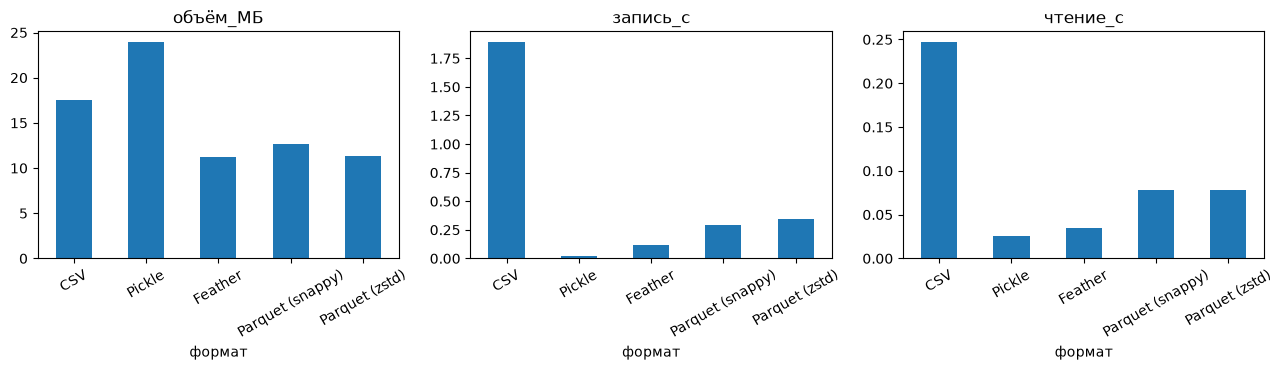

In [ ]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, col in zip(axes, ["объём_МБ", "запись_с", "чтение_с"]):
    res[col].plot.bar(ax=ax, title=col, rot=30)
plt.tight_layout()
Path("../docs").mkdir(exist_ok=True)
plt.savefig("../docs/formats.png", dpi=150)
plt.show()

In [ ]:
a = clean_final
b = pd.read_parquet("../data/interim/run1.parquet")
c = pd.read_parquet("../data/interim/run2.parquet")
print(a.shape, b.shape, c.shape)
pd.testing.assert_frame_equal(a, b)
pd.testing.assert_frame_equal(b, c)
print("блокнот и сценарий совпадают; повторный запуск даёт тот же результат")

(1089, 2619) (1089, 2619) (1089, 2619)
блокнот и сценарий совпадают; повторный запуск даёт тот же результат


In [ ]:
from src.cleaning import column_units
import time, statistics

def med(fn, n=3):
    fn(); ts = []
    for _ in range(n):
        t0 = time.perf_counter(); fn(); ts.append(time.perf_counter() - t0)
    return statistics.median(ts)

P = Path("../data/interim/run1.parquet")
base = pd.read_parquet(P)
print(f"файл: {P.stat().st_size/1024**2:.1f} МБ | память: {base.memory_usage(deep=True).sum()/1024**2:.1f} МБ")
print(f"чтение: {med(lambda: pd.read_parquet(P)):.3f} с | "
      f"группировка: {med(lambda: base.groupby('gc_cnt_gad_2025')['gc_pop_tot_2025'].median()):.4f} с")

dt = base.dtypes.astype(str)
mem = base.memory_usage(deep=True, index=False)
display(pd.DataFrame({"столбцов": dt.value_counts(),
                      "память_МБ": (mem.groupby(dt.values).sum() / 1024**2).round(2)}))

units = column_units([c.upper() for c in base.columns], sheets["Index"])
units = {k.lower(): v for k, v in units.items()}
num = base.select_dtypes("number")
inv = pd.DataFrame({"тип": dt[num.columns].values,
                    "единица": [units.get(c) or "нет в Index" for c in num.columns],
                    "макс": num.abs().max().values})
display(inv.groupby(["единица", "тип"]).agg(столбцов=("макс", "size"), макс=("макс", "max"))
        .sort_values("макс", ascending=False))

файл: 11.3 МБ | память: 21.9 МБ
чтение: 0.078 с | группировка: 0.0004 с


,столбцов,память_МБ
bool,13,0.01
float64,1800,14.96
int64,789,6.56
str,17,0.38


столбцов          макс
единица                    тип                            
PPP                        int64           7  5.520000e+11
m3                         int64         109  8.520085e+09
PPP                        float64         7  7.744656e+08
m2                         int64         508  6.762673e+08
                           float64        72  1.022340e+08
m                          float64        15  4.370608e+07
ton/year                   float64       329  3.986596e+07
num inhabitants            float64       219  1.951976e+07
number of people           float64         1  1.948516e+07
нет в Index                float64       196  1.456770e+07
                           int64          34  1.220125e+07
num. devices               float64         8  5.649690e+05
hectares                   float64        30  1.766413e+05
mm year-1                  float64        18  2.583421e+04
-                          int64          17  8.408000e+03
num people                 int64           7  6.510000e+03
Number of premature deaths float64         5  6.443000e+03
num events                 int64          37  4.728000e+03
ton/(year x person)        float64        28  2.224427e+03
km2                        int64          47  2.186000e+03
year                       int64           2  2.030000e+03
num events                 float64         3  1.910000e+03
hectares                   int64           3  1.184000e+03
ms                         float64         8  9.290000e+02
num facilities             float64         2  8.710000e+02
°C                         float64        31  8.019370e+02
m2/person                  float64        36  5.737100e+02
Mbps                       float64        16  4.938900e+02
Num. of days               int64           6  3.650000e+02
%                          float64       604  2.000000e+02
                           int64           4  1.000000e+02
years                      float64        51  8.445300e+01
µg/m3                      int64           5  4.700000e+01
num hazards                float64        32  2.600000e+01
m/s                        float64         5  1.237800e+01
US$                        float64        10  1.078000e+01
num facilities/km2         float64         2  6.444444e+00
kWh/kWp                    float64         1  6.129000e+00
mm/year                    float64         1  5.577000e+00
num fires                  int64           3  5.000000e+00
dimensionless              float64        36  5.000000e+00
-                          float64        30  1.000000e+00
°C/year                    float64         1  3.000000e-02
m/m2                       float64         1  2.699023e-02
num facilities/person      float64         2  7.484240e-04

In [ ]:
from pathlib import Path

cfg = Path("../src/config.py")
cfg_add = r'''

# --- Схема типов (шаг 10): тип выбирается по единице измерения из листа Index ---
# Границы задаются предметной областью, а не текущей выборкой.
FLOAT32_UNITS = {
    "%", "ton/year", "ton/(year x person)", "°C", "°C/year", "years", "m2/person",
    "Mbps", "dimensionless", "-", "num hazards", "ms", "mm/year", "mm year-1",
    "hectares", "num devices", "US$", "num facilities", "num facilities/km2",
    "num facilities/person", "num events", "m/s", "kWh/kWp", "m/m2",
    "Number of premature deaths",
}
INT16_UNITS = {"Num. of days", "year", "µg/m3", "%"}
INT32_UNITS = {"km2", "hectares", "num events", "num fires", "num people"}
CATEGORY_MAX_SHARE = 0.5
TYPED_PARQUET = INTERIM_DIR / "clean_typed.parquet"
'''
t = cfg.read_text(encoding="utf-8")
if "FLOAT32_UNITS" not in t:
    cfg.write_text(t.rstrip("\n") + "\n" + cfg_add, encoding="utf-8")

cl = Path("../src/cleaning.py")
cl_add = r'''

INT_LIMITS = {"int16": (-32768, 32767), "int32": (-(2**31), 2**31 - 1)}


def _norm_unit(u):
    """Приводит единицу к нормальной форме (NFKC), чтобы 'µ' совпадали."""
    return None if u is None else unicodedata.normalize("NFKC", str(u)).strip()


def apply_schema(df, units, float32_units, int16_units, int32_units, cat_max_share=0.5):
    """Назначает типы по единицам измерения; возвращает (таблица, план {столбец: тип})."""
    f32 = {_norm_unit(u) for u in float32_units}
    i16 = {_norm_unit(u) for u in int16_units}
    i32 = {_norm_unit(u) for u in int32_units}
    out = df.copy()
    plan = {}
    for c in out.columns:
        s = out[c]
        u = _norm_unit(units.get(c))
        if pd.api.types.is_bool_dtype(s):
            continue
        if pd.api.types.is_float_dtype(s) and u in f32:
            plan[c] = "float32"
        elif pd.api.types.is_integer_dtype(s) and u in i16:
            plan[c] = "int16"
        elif pd.api.types.is_integer_dtype(s) and u in i32:
            plan[c] = "int32"
        elif _is_text(s):
            nn = s.dropna()
            if len(nn) and nn.nunique() / len(nn) < cat_max_share:
                plan[c] = "category"
    for c, t in plan.items():
        if t in INT_LIMITS:
            lo, hi = INT_LIMITS[t]
            if out[c].min() < lo or out[c].max() > hi:
                raise ValueError(f"{c}: значения не помещаются в {t}")
        out[c] = out[c].astype(t)
    logger.info("схема типов применена к %d столбцам", len(plan))
    return out, plan
'''
t = cl.read_text(encoding="utf-8")
if "def apply_schema" not in t:
    t = t.replace("import re\n", "import re\nimport unicodedata\n", 1)
    cl.write_text(t.rstrip("\n") + "\n" + cl_add, encoding="utf-8")
print("config:", "FLOAT32_UNITS" in cfg.read_text(encoding="utf-8"),
      "| cleaning:", "def apply_schema" in cl.read_text(encoding="utf-8"))

config: True | cleaning: True


In [ ]:
import importlib, src.cleaning, src.config
importlib.reload(src.config); importlib.reload(src.cleaning)
from src.cleaning import apply_schema, column_units
from src import config
import time, statistics, numpy as np

def med(fn, n=3):
    fn(); ts = []
    for _ in range(n):
        t0 = time.perf_counter(); fn(); ts.append(time.perf_counter() - t0)
    return statistics.median(ts)

base = pd.read_parquet("../data/interim/run1.parquet")
units = {k.lower(): v for k, v in column_units([c.upper() for c in base.columns], sheets["Index"]).items()}
typed, plan = apply_schema(base, units, config.FLOAT32_UNITS, config.INT16_UNITS,
                           config.INT32_UNITS, config.CATEGORY_MAX_SHARE)

print(pd.Series(plan).value_counts().to_dict())

# проверка потерь точности
f32 = [c for c, t in plan.items() if t == "float32"]
rel = ((base[f32] - typed[f32].astype("float64")).abs() / base[f32].abs().where(base[f32] != 0)).max().max()
ints = [c for c, t in plan.items() if t.startswith("int")]
print("макс. относительная ошибка float32:", rel, "| целые без изменений:",
      bool(all((base[c] == typed[c]).all() for c in ints)))

typed.to_parquet(config.TYPED_PARQUET, compression="zstd")
P0, P1 = Path("../data/interim/run1.parquet"), config.TYPED_PARQUET
g = "gc_cnt_gad_2025"
rows = {
    "Объём файла на диске, МБ": (P0.stat().st_size / 1024**2, P1.stat().st_size / 1024**2),
    "Объём в памяти, МБ": (base.memory_usage(deep=True).sum() / 1024**2, typed.memory_usage(deep=True).sum() / 1024**2),
    "Время чтения, с": (med(lambda: pd.read_parquet(P0)), med(lambda: pd.read_parquet(P1))),
    "Время группировки, мс": (med(lambda: [base.groupby(g)["gc_pop_tot_2025"].median() for _ in range(200)]) / 200 * 1000,
                              med(lambda: [typed.groupby(g, observed=True)["gc_pop_tot_2025"].median() for _ in range(200)]) / 200 * 1000),
    "Столбцов типа category": (0, int((typed.dtypes.astype(str) == "category").sum())),
}
t7 = pd.DataFrame(rows, index=["до", "после"]).T
t7["изменение, %"] = ((t7["после"] / t7["до"] - 1) * 100).round(0)
display(t7.round(4))
display(typed.dtypes.astype(str).value_counts().to_frame("столбцов"))

{'float32': 1282, 'int32': 97, 'int16': 17, 'category': 11}
макс. относительная ошибка float32: 5.9562924425244816e-08 | целые без изменений: True


,до,после,"изменение, %"
"Объём файла на диске, МБ",11.2643,8.5252,-24.0
"Объём в памяти, МБ",21.9012,15.8680,-28.0
"Время чтения, с",0.0753,0.0745,-1.0
"Время группировки, мс",0.2678,0.2566,-4.0
Столбцов типа category,0.0000,11.0000,inf


,столбцов
float32,1282
int64,675
float64,518
int32,97
int16,17
bool,13
category,11
str,6


In [ ]:
cat = [c for c, t in plan.items() if t == "category"]
left = [c for c in typed.columns if str(typed[c].dtype) in ("str", "string", "object")]
print("category:", cat)
print("остались текстом (доля уникальных среди непустых):",
      {c: round(typed[c].nunique() / typed[c].notna().sum(), 2) for c in left})

category: ['gc_cnt_gad_2025', 'gc_cnt_unn_2025', 'gc_dev_wig_2025', 'gc_pls_scr_2025', 'ge_eco_cla_2025', 'ge_mrb_mai_2025', 'ge_mrb_lis_2025', 'ge_scl_mpc_2023', 'ge_scl_lst_2023', 'wa_gwr_gwb_2025', 'wa_gwr_mma_2025']
остались текстом (доля уникальных среди непустых): {'gc_ucn_mai_2025': np.float64(0.98), 'gc_ucn_lis_2025': np.float64(0.99), 'ns_mpa_nam_2025': np.float64(0.84), 'ns_mpa_des_2025': np.float64(0.64), 'ns_tpa_nam_2025': np.float64(0.92), 'ns_tpa_des_2025': np.float64(0.56)}


In [ ]:
import os, time, statistics, threading, platform
import numpy as np
import psutil, polars as pl
from src import config

PQ = config.TYPED_PARQUET
COUNTRY, POP, DEV = "gc_cnt_gad_2025", "gc_pop_tot_2025", "gc_dev_wig_2025"

def bench(fn, n=5):
    t0 = time.perf_counter(); fn(); t1 = time.perf_counter() - t0      # прогрев не учитывается
    inner = min(1000, max(1, int(0.05 / max(t1, 1e-6))))
    ts = []
    for _ in range(n):
        t0 = time.perf_counter()
        for _ in range(inner):
            fn()
        ts.append((time.perf_counter() - t0) / inner)
    return statistics.median(ts)

def peak_mb(fn):
    proc = psutil.Process(); base = proc.memory_info().rss
    peak, stop = [base], threading.Event()
    def sample():
        while not stop.is_set():
            peak[0] = max(peak[0], proc.memory_info().rss); time.sleep(0.003)
    th = threading.Thread(target=sample); th.start()
    try:
        fn()
    finally:
        stop.set(); th.join()
    return (peak[0] - base) / 1024**2

def run_suite(path):
    pdf, plf = pd.read_parquet(path), pl.read_parquet(path)
    ref_pd = pdf[[COUNTRY, DEV]].drop_duplicates(COUNTRY).rename(columns={DEV: "dev_ref"})
    ref_pl = (plf.select(pl.col(COUNTRY).cast(pl.String), pl.col(DEV).cast(pl.String).alias("dev_ref"))
                 .unique(subset=COUNTRY, keep="first", maintain_order=True))
    plf_s = plf.with_columns(pl.col(COUNTRY).cast(pl.String))

    a = pdf.groupby(COUNTRY, observed=True)[POP].median(); a.index = a.index.astype(str)
    b = plf.group_by(COUNTRY).agg(pl.col(POP).median()).to_pandas().set_index(COUNTRY)[POP]
    b.index = b.index.astype(str)
    print("результаты группировки совпадают:",
          np.allclose(a.sort_index().values, b.sort_index().values, equal_nan=True))

    def chain_pd():
        d = pd.read_parquet(path, columns=[COUNTRY, POP])
        d = d[d[POP] > 1e5].merge(ref_pd, on=COUNTRY, how="left")
        return d.groupby("dev_ref", observed=True)[POP].median().sort_values(ascending=False)

    def chain_pl():
        return (pl.scan_parquet(path)
                .select(pl.col(COUNTRY).cast(pl.String), pl.col(POP))
                .filter(pl.col(POP) > 1e5)
                .join(ref_pl.lazy(), on=COUNTRY, how="left")
                .group_by("dev_ref").agg(pl.col(POP).median())
                .sort(POP, descending=True).collect())

    g_pd = lambda: pdf.groupby(COUNTRY, observed=True)[POP].median()
    ops = {
        "Чтение Parquet": (lambda: pd.read_parquet(path), lambda: pl.read_parquet(path)),
        "Фильтрация": (lambda: pdf[pdf[POP] > 1e5], lambda: plf.filter(pl.col(POP) > 1e5)),
        "Группировка (медиана)": (g_pd, lambda: plf.group_by(COUNTRY).agg(pl.col(POP).median())),
        "Группировка, polars lazy": (g_pd, lambda: plf.lazy().group_by(COUNTRY)
                                     .agg(pl.col(POP).median()).collect()),
        "Сортировка таблицы": (lambda: pdf.sort_values(POP, ascending=False),
                               lambda: plf.sort(POP, descending=True)),
        "Соединение со справочником": (lambda: pdf.merge(ref_pd, on=COUNTRY, how="left"),
                                       lambda: plf_s.join(ref_pl, on=COUNTRY, how="left")),
        "Цепочка (polars lazy)": (chain_pd, chain_pl),
    }
    rows = []
    for name, (fp, fl) in ops.items():
        tp, tl = bench(fp), bench(fl)
        rows.append((name, tp * 1000, tl * 1000, tp / tl, peak_mb(fp), peak_mb(fl)))
    return pd.DataFrame(rows, columns=["операция", "pandas, мс", "polars, мс", "ускорение, ×",
                                       "pandas, МБ", "polars, МБ"]).set_index("операция")

print("Python", platform.python_version(), "| pandas", pd.__version__, "| polars", pl.__version__,
      "| ядер:", os.cpu_count(), "| ОЗУ, ГБ:", round(psutil.virtual_memory().total / 1024**3))

print("\n=== наш набор: 1089 строк x 2619 столбцов ===")
res_full = run_suite(PQ); display(res_full.round(2))

BIG = Path("../data/interim/bench/big.parquet")
pd.concat([pd.read_parquet(PQ, columns=[COUNTRY, POP, DEV])] * 1000, ignore_index=True).to_parquet(BIG)
print("\n=== синтетический набор: 1,09 млн строк x 3 столбца (наш набор x 1000) ===")
res_big = run_suite(BIG); display(res_big.round(2))

Python 3.12.10 | pandas 3.0.6 | polars 1.44.2 | ядер: 12 | ОЗУ, ГБ: 16

=== наш набор: 1089 строк x 2619 столбцов ===
результаты группировки совпадают: True


,"pandas, мс","polars, мс","ускорение, ×","pandas, МБ","polars, МБ"
операция,,,,,
Чтение Parquet,69.15,32.10,2.15,16.62,1.41
Фильтрация,2.84,12.39,0.23,5.75,1.81
Группировка (медиана),0.22,0.18,1.19,0.02,0.00
"Группировка, polars lazy",0.20,0.58,0.35,0.02,0.00
Сортировка таблицы,7.60,2.04,3.72,11.88,0.00
Соединение со справочником,1.04,0.64,1.62,0.02,0.00
Цепочка (polars lazy),24.87,3.64,6.82,3.10,0.07



=== синтетический набор: 1,09 млн строк x 3 столбца (наш набор x 1000) ===
результаты группировки совпадают: True


,"pandas, мс","polars, мс","ускорение, ×","pandas, МБ","polars, МБ"
операция,,,,,
Чтение Parquet,11.41,44.52,0.26,1.27,1.25
Фильтрация,5.68,0.46,12.32,11.79,0.00
Группировка (медиана),23.66,6.42,3.69,24.95,0.00
"Группировка, polars lazy",28.28,6.03,4.69,24.95,0.00
Сортировка таблицы,43.78,16.15,2.71,42.60,0.00
Соединение со справочником,36.56,8.59,4.26,55.35,0.06
Цепочка (polars lazy),57.24,42.54,1.35,35.30,6.17


In [ ]:
import subprocess, sys, textwrap
BIG_ABS = str(BIG.resolve())

def peak_mb_sub(body):
    code = textwrap.dedent(f"""
        import psutil, polars as pl, pandas as pd
        PQ = r"{BIG_ABS}"
        {body}
        print(psutil.Process().memory_info().peak_wset / 1024**2)
    """)
    r = subprocess.run([sys.executable, "-c", code], capture_output=True, text=True)
    if r.returncode:
        raise RuntimeError(r.stderr[-500:])
    return float(r.stdout.strip().splitlines()[-1])

g = "gc_cnt_gad_2025"; p = "gc_pop_tot_2025"
base_mb = peak_mb_sub("pass")
cases = {
    "pandas: чтение + группировка":
        f'd = pd.read_parquet(PQ); d.groupby("{g}", observed=True)["{p}"].median()',
    "polars eager: чтение + группировка":
        f'd = pl.read_parquet(PQ); d.group_by("{g}").agg(pl.col("{p}").median())',
    "polars lazy: scan + группировка":
        f'pl.scan_parquet(PQ).group_by("{g}").agg(pl.col("{p}").median()).collect()',
}
print(f"базовый процесс (импорты): {base_mb:.0f} МБ")
for k, body in cases.items():
    print(f"{k}: пик {peak_mb_sub(body):.0f} МБ, сверх базового {peak_mb_sub(body) - base_mb:.0f} МБ")

базовый процесс (импорты): 93 МБ
pandas: чтение + группировка: пик 165 МБ, сверх базового 72 МБ
polars eager: чтение + группировка: пик 171 МБ, сверх базового 73 МБ
polars lazy: scan + группировка: пик 147 МБ, сверх базового 62 МБ


In [ ]:
import hashlib, shutil, subprocess, sys
ROOT = Path("..").resolve()

def sha(p): return hashlib.sha256(p.read_bytes()).hexdigest()[:16]
def wipe(d):
    for p in d.iterdir():
        shutil.rmtree(p) if p.is_dir() else p.unlink()
def pipe(*a):
    r = subprocess.run([sys.executable, "-m", "src.pipeline", *a], cwd=ROOT, capture_output=True, text=True)
    if r.returncode:
        print(r.stderr[-1500:])
    return r.returncode

h0 = sha(config.RAW_XLSX)
wipe(config.INTERIM_DIR); wipe(config.PROCESSED_DIR)
print("папки очищены:", not any(config.INTERIM_DIR.iterdir()) and not any(config.PROCESSED_DIR.iterdir()))
assert pipe() == 0
first = pd.read_parquet(config.CLEAN_PARQUET)
assert pipe() == 0
second = pd.read_parquet(config.CLEAN_PARQUET)
pd.testing.assert_frame_equal(first, second)
print("raw не изменился:", h0 == sha(config.RAW_XLSX), "| результат восстановлен:", first.shape,
      "| повторный запуск даёт тот же результат")

папки очищены: True
raw не изменился: True | результат восстановлен: (1089, 2619) | повторный запуск даёт тот же результат


In [ ]:
for f in ("config.py", "pipeline.py"):
    t = (Path("..") / "src" / f).read_text(encoding="utf-8")
    print(f, len(t.splitlines()), "строк |", repr(t[:45]),
          "| лишнее:", [m for m in ("config_code", "pipeline_code", "write_text") if m in t],
          "| есть stage_typed:", "def stage_typed" in t)

config.py 31 строк | '"""Пути и параметры проекта."""\nfrom pathlib ' | лишнее: [] | есть stage_typed: False
pipeline.py 289 строк | '"""Сквозной сценарий очистки GHS-UCDB: xlsx -' | лишнее: ['config_code', 'pipeline_code', 'write_text'] | есть stage_typed: True


In [ ]:
from pathlib import Path

config_code = r'''"""Пути и параметры проекта."""
from pathlib import Path

ROOT = Path(__file__).resolve().parent.parent
RAW_DIR = ROOT / "data" / "raw"
INTERIM_DIR = ROOT / "data" / "interim"
PROCESSED_DIR = ROOT / "data" / "processed"
LOGS_DIR = ROOT / "logs"

RAW_XLSX = RAW_DIR / "GHS_UCDB_REGION_LATIN_AMERICA_AND_THE_CARIBBEAN_R2024A.xlsx"
SHEETS_RAW_DIR = INTERIM_DIR / "sheets_raw"
CLEAN_UNTYPED = INTERIM_DIR / "clean_untyped.parquet"
CLEAN_PARQUET = PROCESSED_DIR / "clean.parquet"
TYPED_PARQUET = INTERIM_DIR / "clean_typed.parquet"

KEY = "ID_UC_G0"
BASE_SHEET = "GENERAL_CHARACTERISTICS"
SERVICE_SHEETS = ("Description", "Index")

# --- Схема типов (шаг 10): тип выбирается по единице измерения из листа Index ---
# Границы задаются предметной областью, а не текущей выборкой.
FLOAT32_UNITS = {
    "%", "ton/year", "ton/(year x person)", "°C", "°C/year", "years", "m2/person",
    "Mbps", "dimensionless", "-", "num hazards", "ms", "mm/year", "mm year-1",
    "hectares", "num devices", "US$", "num facilities", "num facilities/km2",
    "num facilities/person", "num events", "m/s", "kWh/kWp", "m/m2",
    "Number of premature deaths",
}
INT16_UNITS = {"Num. of days", "year", "µg/m3", "%"}
INT32_UNITS = {"km2", "hectares", "num events", "num fires", "num people"}
CATEGORY_MAX_SHARE = 0.5
'''

pipeline_code = r'''"""Сквозной сценарий обработки GHS-UCDB.

Данные идут только в одну сторону: raw -> interim -> processed.
  serialize  data/raw/*.xlsx          -> data/interim/sheets_raw/*.parquet
  clean      data/interim/sheets_raw  -> data/interim/clean_untyped.parquet
  typed      clean_untyped.parquet    -> data/processed/clean.parquet

Запуск из корня проекта:
    python -m src.pipeline                    # все этапы
    python -m src.pipeline --stage clean      # один этап
    python -m src.pipeline --sample 200       # отладочный срез (отдельные файлы)
"""
import argparse
import logging
import sys
import time
from pathlib import Path

import pandas as pd

from src import config
from src.cleaning import apply_schema, build_clean, clean_sheet, column_units

log = logging.getLogger("pipeline")
STAGES = ("serialize", "clean", "typed")


def setup_logging(log_file):
    log_file.parent.mkdir(parents=True, exist_ok=True)
    logging.basicConfig(
        level=logging.INFO,
        format="%(asctime)s %(levelname)s %(name)s: %(message)s",
        handlers=[logging.FileHandler(log_file, encoding="utf-8"), logging.StreamHandler()],
        force=True,
    )


def paths(sample):
    if sample:
        d = config.INTERIM_DIR / "sample"
        return {"untyped": d / "clean_untyped.parquet", "final": d / "clean.parquet"}
    return {"untyped": config.CLEAN_UNTYPED, "final": config.CLEAN_PARQUET}


def check_sheets(sheets):
    for need in (config.BASE_SHEET, "Index"):
        if need not in sheets:
            raise ValueError(f"в данных нет обязательного листа {need}")
    if config.KEY not in sheets[config.BASE_SHEET].columns:
        raise ValueError(f"в листе {config.BASE_SHEET} нет ключа {config.KEY}")


def read_book(path):
    if not path.exists():
        raise FileNotFoundError(f"исходный файл не найден: {path}")
    if path.suffix.lower() != ".xlsx":
        raise ValueError(f"ожидался файл .xlsx, получен {path.suffix}")
    log.info("чтение %s", path.name)
    t0 = time.perf_counter()
    try:
        sheets = pd.read_excel(path, sheet_name=None)
    except Exception as e:
        raise ValueError(f"не удалось прочитать книгу (файл повреждён?): {e}") from e
    log.info("прочитано листов: %d за %.1f с", len(sheets), time.perf_counter() - t0)
    check_sheets(sheets)
    return sheets


def load_sheets(sheets_dir):
    files = sorted(sheets_dir.glob("*.parquet"))
    if not files:
        raise FileNotFoundError(f"нет файлов в {sheets_dir}: сначала выполните этап serialize")
    sheets = {p.stem: pd.read_parquet(p) for p in files}
    check_sheets(sheets)
    return sheets


def stage_serialize(src_path, sheets_dir):
    sheets = read_book(src_path)
    sheets_dir.mkdir(parents=True, exist_ok=True)
    for old in sheets_dir.glob("*.parquet"):
        old.unlink()
    for name, d in sheets.items():
        if name in config.SERVICE_SHEETS:
            d = d.astype("string")
        d.to_parquet(sheets_dir / f"{name}.parquet")
    log.info("serialize: %d листов -> %s", len(sheets), sheets_dir)


def stage_clean(sheets_dir, out_path, sample):
    sheets = load_sheets(sheets_dir)
    cleaned = {}
    for name, d in sheets.items():
        if name in config.SERVICE_SHEETS:
            continue
        if sample:
            d = d.head(sample)
        cleaned[name], st = clean_sheet(d, config.KEY)
        log.info("%-24s строк %d->%d | столбцов %d->%d | дублей %d | пустых столбцов %d",
                 name, st["строк_было"], st["строк_стало"], st["столбцов_было"],
                 st["столбцов_стало"], st["дублей_удалено"], st["пустых_удалено"])
    df, _ = build_clean(cleaned, config.KEY, sheets["Index"])
    out_path.parent.mkdir(parents=True, exist_ok=True)
    df.to_parquet(out_path, compression="zstd")
    log.info("clean: %s, %s", out_path.name, df.shape)


def stage_typed(sheets_dir, in_path, out_path):
    if not in_path.exists():
        raise FileNotFoundError(f"нет файла {in_path}: сначала выполните этап clean")
    df = pd.read_parquet(in_path)
    index_df = pd.read_parquet(sheets_dir / "Index.parquet")
    units = column_units([c.upper() for c in df.columns], index_df)
    units = {k.lower(): v for k, v in units.items()}
    typed, plan = apply_schema(df, units, config.FLOAT32_UNITS, config.INT16_UNITS,
                               config.INT32_UNITS, config.CATEGORY_MAX_SHARE)
    out_path.parent.mkdir(parents=True, exist_ok=True)
    typed.to_parquet(out_path, compression="zstd")
    log.info("typed: %s, %s, %.1f МБ, типов назначено: %d", out_path.name, typed.shape,
             out_path.stat().st_size / 1024**2, len(plan))


def run(stage, src_path, sample):
    t0 = time.perf_counter()
    p = paths(sample)
    todo = STAGES if stage == "all" else (stage,)
    if "serialize" in todo:
        stage_serialize(src_path, config.SHEETS_RAW_DIR)
    if "clean" in todo:
        stage_clean(config.SHEETS_RAW_DIR, p["untyped"], sample)
    if "typed" in todo:
        stage_typed(config.SHEETS_RAW_DIR, p["untyped"], p["final"])
    log.info("готово за %.1f с", time.perf_counter() - t0)


def main(argv=None):
    ap = argparse.ArgumentParser(description="Обработка датасета GHS-UCDB")
    ap.add_argument("--input", type=Path, default=config.RAW_XLSX, help="исходный .xlsx")
    ap.add_argument("--stage", choices=("all",) + STAGES, default="all", help="этап (по умолчанию все)")
    ap.add_argument("--sample", type=int, default=None, metavar="N",
                    help="отладочный режим: первые N строк каждого листа, результат в data/interim/sample")
    ap.add_argument("--log-file", type=Path, default=config.LOGS_DIR / "cleaning.log")
    a = ap.parse_args(argv)
    setup_logging(a.log_file)
    try:
        run(a.stage, a.input, a.sample)
    except (FileNotFoundError, ValueError) as e:
        log.error("%s", e)
        return 1
    except Exception:
        log.exception("необработанная ошибка")
        return 2
    return 0


if __name__ == "__main__":
    sys.exit(main())
'''

(Path("..") / "src" / "config.py").write_text(config_code, encoding="utf-8")
(Path("..") / "src" / "pipeline.py").write_text(pipeline_code, encoding="utf-8")

for f in ("config.py", "pipeline.py"):
    t = (Path("..") / "src" / f).read_text(encoding="utf-8")
    print(f, len(t.splitlines()), "строк | начало:", repr(t[:40]),
          "| лишнее:", [m for m in ("config_code", "pipeline_code", "write_text") if m in t])

config.py 31 строк | начало: '"""Пути и параметры проекта."""\nfrom pat' | лишнее: []
pipeline.py 157 строк | начало: '"""Сквозной сценарий обработки GHS-UCDB.' | лишнее: []


In [ ]:
import inspect, sys
from pathlib import Path
sys.path.insert(0, str(Path("..").resolve()))
from src import cleaning
print(inspect.signature(cleaning.build_clean)); print(inspect.signature(cleaning.apply_schema))

(sheets_clean, key, index_df)
(df, units, float32_units, int16_units, int32_units, cat_max_share=0.5)


In [ ]:
from pathlib import Path
t = (Path("..") / "src" / "config.py").read_text(encoding="utf-8")
print("SHEETS_RAW_DIR" in t)
print([l for l in t.splitlines() if "_DIR" in l or "PARQUET" in l])

True
['RAW_DIR = ROOT / "data" / "raw"', 'INTERIM_DIR = ROOT / "data" / "interim"', 'PROCESSED_DIR = ROOT / "data" / "processed"', 'LOGS_DIR = ROOT / "logs"', 'RAW_XLSX = RAW_DIR / "GHS_UCDB_REGION_LATIN_AMERICA_AND_THE_CARIBBEAN_R2024A.xlsx"', 'SHEETS_RAW_DIR = INTERIM_DIR / "sheets_raw"', 'CLEAN_UNTYPED = INTERIM_DIR / "clean_untyped.parquet"', 'CLEAN_PARQUET = PROCESSED_DIR / "clean.parquet"', 'TYPED_PARQUET = INTERIM_DIR / "clean_typed.parquet"']


In [ ]:
import pandas as pd
for k, v in list(globals().items()):
    if isinstance(v, pd.DataFrame) and v.shape == (1089, 2619):
        n_cat = sum(str(t) == "category" for t in v.dtypes)
        n_f32 = sum(str(t) == "float32" for t in v.dtypes)
        print(k, v.shape, "category:", n_cat, "float32:", n_f32)

df_pipe (1089, 2619) category: 11 float32: 1282


In [ ]:
import pandas as pd

def report(name, v):
    n_cat = sum(str(t) == "category" for t in v.dtypes)
    n_f32 = sum(str(t) == "float32" for t in v.dtypes)
    print(name, v.shape, "category:", n_cat, "float32:", n_f32)

for k, v in list(globals().items()):
    if k.startswith("_"):
        continue
    if isinstance(v, pd.DataFrame) and v.shape[1] > 2000:
        report(k, v)
    elif isinstance(v, tuple):
        for i, x in enumerate(v):
            if isinstance(x, pd.DataFrame) and x.shape[1] > 2000:
                report(f"{k}[{i}]", x)

df_pipe (1089, 2619) category: 11 float32: 1282


In [ ]:
from pathlib import Path
src = (Path("..") / "src" / "pipeline.py").read_text(encoding="utf-8").splitlines()
for i, l in enumerate(src, 1):
    if any(w in l for w in ("build_clean", "apply_schema", "units", "index_df", "def ")):
        print(i, l)

22 from src.cleaning import apply_schema, build_clean, clean_sheet, column_units
28 def setup_logging(log_file):
38 def paths(sample):
45 def check_sheets(sheets):
53 def read_book(path):
69 def load_sheets(sheets_dir):
78 def stage_serialize(src_path, sheets_dir):
90 def stage_clean(sheets_dir, out_path, sample):
102     df, _ = build_clean(cleaned, config.KEY, sheets["Index"])
108 def stage_typed(sheets_dir, in_path, out_path):
112     index_df = pd.read_parquet(sheets_dir / "Index.parquet")
113     units = column_units([c.upper() for c in df.columns], index_df)
114     units = {k.lower(): v for k, v in units.items()}
115     typed, plan = apply_schema(df, units, config.FLOAT32_UNITS, config.INT16_UNITS,
123 def run(stage, src_path, sample):
136 def main(argv=None):


In [ ]:
import inspect
from pathlib import Path
from src import cleaning

lines = (Path("..") / "src" / "pipeline.py").read_text(encoding="utf-8").splitlines()
print("\n".join(f"{i} {l}" for i, l in enumerate(lines[52:122], 53)))
print()
print(inspect.signature(cleaning.clean_sheet))
print(inspect.signature(cleaning.column_units))

53 def read_book(path):
54     if not path.exists():
55         raise FileNotFoundError(f"исходный файл не найден: {path}")
56     if path.suffix.lower() != ".xlsx":
57         raise ValueError(f"ожидался файл .xlsx, получен {path.suffix}")
58     log.info("чтение %s", path.name)
59     t0 = time.perf_counter()
60     try:
61         sheets = pd.read_excel(path, sheet_name=None)
62     except Exception as e:
63         raise ValueError(f"не удалось прочитать книгу (файл повреждён?): {e}") from e
64     log.info("прочитано листов: %d за %.1f с", len(sheets), time.perf_counter() - t0)
65     check_sheets(sheets)
66     return sheets
67 
68 
69 def load_sheets(sheets_dir):
70     files = sorted(sheets_dir.glob("*.parquet"))
71     if not files:
72         raise FileNotFoundError(f"нет файлов в {sheets_dir}: сначала выполните этап serialize")
73     sheets = {p.stem: pd.read_parquet(p) for p in files}
74     check_sheets(sheets)
75     return sheets
76 
77 
78 def stage_serialize(src_path,

In [ ]:
from pathlib import Path
lines = (Path("..") / "src" / "pipeline.py").read_text(encoding="utf-8").splitlines()
print("\n".join(f"{i} {l}" for i, l in enumerate(lines[89:122], 90)))

90 def stage_clean(sheets_dir, out_path, sample):
91     sheets = load_sheets(sheets_dir)
92     cleaned = {}
93     for name, d in sheets.items():
94         if name in config.SERVICE_SHEETS:
95             continue
96         if sample:
97             d = d.head(sample)
98         cleaned[name], st = clean_sheet(d, config.KEY)
99         log.info("%-24s строк %d->%d | столбцов %d->%d | дублей %d | пустых столбцов %d",
100                  name, st["строк_было"], st["строк_стало"], st["столбцов_было"],
101                  st["столбцов_стало"], st["дублей_удалено"], st["пустых_удалено"])
102     df, _ = build_clean(cleaned, config.KEY, sheets["Index"])
103     out_path.parent.mkdir(parents=True, exist_ok=True)
104     df.to_parquet(out_path, compression="zstd")
105     log.info("clean: %s, %s", out_path.name, df.shape)
106 
107 
108 def stage_typed(sheets_dir, in_path, out_path):
109     if not in_path.exists():
110         raise FileNotFoundError(f"нет файла {in_path}: сначала выполн

In [ ]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path("..").resolve()))
import pandas as pd
from src import config

idx = pd.read_parquet(config.SHEETS_RAW_DIR / "Index.parquet")
desc = pd.read_parquet(config.SHEETS_RAW_DIR / "Description.parquet")

print("Index:", idx.shape, list(idx.columns))
print(idx.head(6).to_string(max_colwidth=50))
print()
print("Description:", desc.shape, list(desc.columns))
print(desc.head(8).to_string(max_colwidth=70))

Index: (506, 29) ['Thematic Area', 'Group', 'Indicator Name', 'Unnamed: 3', 'Attribute ID', 'Unit', 'Source', 'Methodology', 'Note', 'Temporal coverage', 'Unnamed: 10', 'Unnamed: 11', 'Unnamed: 12', 'Unnamed: 13', 'Unnamed: 14', 'Unnamed: 15', 'Unnamed: 16', 'Unnamed: 17', 'Unnamed: 18', 'Unnamed: 19', 'Unnamed: 20', 'Unnamed: 21', 'Unnamed: 22', 'Unnamed: 23', 'Unnamed: 24', 'Unnamed: 25', 'Unnamed: 26', 'Unnamed: 27', 'Unnamed: 28']
             Thematic Area              Group              Indicator Name Unnamed: 3     Attribute ID  Unit               Source   Methodology  Note Temporal coverage Unnamed: 10 Unnamed: 11 Unnamed: 12 Unnamed: 13 Unnamed: 14 Unnamed: 15 Unnamed: 16 Unnamed: 17 Unnamed: 18 Unnamed: 19 Unnamed: 20 Unnamed: 21 Unnamed: 22 Unnamed: 23 Unnamed: 24 Unnamed: 25 Unnamed: 26 Unnamed: 27 Unnamed: 28
0                     <NA>               <NA>                        <NA>       <NA>             <NA>  <NA>                 <NA>          <NA>  <NA>            1970.0

In [ ]:
import re
import sys
from pathlib import Path
sys.path.insert(0, str(Path("..").resolve()))
import pandas as pd
from src import config

idx = pd.read_parquet(config.SHEETS_RAW_DIR / "Index.parquet")
idx[["Thematic Area", "Group"]] = idx[["Thematic Area", "Group"]].ffill()
idx = idx[idx["Attribute ID"].notna()].copy()
idx["Attribute ID"] = idx["Attribute ID"].astype(str).str.strip()

pats = [(re.compile(re.escape(a).replace("XXXX", r"\d{4}"), re.I), r)
        for a, r in zip(idx["Attribute ID"], idx.itertuples())]

df = pd.read_parquet(config.PROCESSED_DIR / "clean.parquet")
nan_share = df.isna().mean()
service = re.compile(r"(_cens|_out|_flag|out_of_range)$", re.I)

rows = []
for c in df.columns:
    hit = next((r for p, r in pats if p.fullmatch(c)), None)
    rows.append({
        "column": c,
        "dtype": str(df[c].dtype),
        "nan_share": round(float(nan_share[c]), 4),
        "thematic_area": getattr(hit, "_1", None),
        "group": getattr(hit, "Group", None),
        "indicator": getattr(hit, "_3", None),
        "unit": getattr(hit, "Unit", None),
        "added_by_cleaning": bool(service.search(c)),
    })
dic = pd.DataFrame(rows)

In [ ]:
by_id = {a: r for a, r in zip(idx["Attribute ID"], idx.to_dict("records"))}
pats = [(re.compile(re.escape(a).replace("XXXX", r"\d{4}"), re.I), a) for a in by_id]

rows = []
for c in df.columns:
    a = next((a for p, a in pats if p.fullmatch(c)), None)
    r = by_id.get(a, {})
    rows.append({
        "column": c, "dtype": str(df[c].dtype),
        "nan_share": round(float(nan_share[c]), 4),
        "thematic_area": r.get("Thematic Area"), "group": r.get("Group"),
        "indicator": r.get("Indicator Name"), "unit": r.get("Unit"),
        "added_by_cleaning": bool(service.search(c)),
    })
dic = pd.DataFrame(rows)

(Path("..") / "docs").mkdir(exist_ok=True)
dic.to_csv(Path("..") / "docs" / "columns_dictionary.csv", index=False, encoding="utf-8-sig")

matched = dic["indicator"].notna()
print("всего столбцов:", len(dic), "| сопоставлено с Index:", int(matched.sum()))
print("служебных (добавлены очисткой):", int(dic["added_by_cleaning"].sum()))
print("без описания, не служебные:", int((~matched & ~dic["added_by_cleaning"]).sum()))
print(dic[~matched & ~dic["added_by_cleaning"]]["column"].head(30).tolist())
print(dic.groupby("thematic_area").size())

всего столбцов: 2619 | сопоставлено с Index: 920
служебных (добавлены очисткой): 13
без описания, не служебные: 1686
['id_uc_g0', 'gc_ucm_cap', 'cl_ren_w05_2020', 'cl_ren_w10_2020', 'cl_ren_w15_2020', 'cl_ren_w20_2020', 'cl_lcz_a01_2025', 'cl_lcz_a02_2025', 'cl_lcz_a03_2025', 'cl_lcz_a04_2025', 'cl_lcz_a05_2025', 'cl_lcz_a06_2025', 'cl_lcz_a07_2025', 'cl_lcz_a08_2025', 'cl_lcz_a09_2025', 'cl_lcz_a10_2025', 'cl_lcz_a11_2025', 'cl_lcz_a12_2025', 'cl_lcz_a13_2025', 'cl_lcz_a14_2025', 'cl_lcz_a15_2025', 'cl_lcz_a16_2025', 'cl_lcz_a17_2025', 'em_co2_agr_1975', 'em_co2_agr_1980', 'em_co2_agr_1985', 'em_co2_agr_1990', 'em_co2_agr_1995', 'em_co2_agr_2000', 'em_co2_agr_2005']
thematic_area
Climate                     85
Emissions                  583
Exposure                   876
GHSL                       404
General Characteristics     10
Geography                   21
Greenness                   56
Hazard and Risk             76
Health                      10
Infrastructures             10


In [ ]:
by_id = {a: r for a, r in zip(idx["Attribute ID"], idx.to_dict("records"))}

def to_re(a):
    parts = re.split(r"X+", a)
    return re.compile("[0-9a-z]+".join(re.escape(p) for p in parts), re.I), sum(len(p) for p in parts)

pats = [(a, *to_re(a)) for a in by_id]

def find(col):
    hits = [(lit, a) for a, p, lit in pats if p.fullmatch(col)]
    return max(hits)[1] if hits else None

rows = []
for c in df.columns:
    a = find(c)
    r = by_id.get(a, {})
    rows.append({
        "column": c, "dtype": str(df[c].dtype),
        "nan_share": round(float(nan_share[c]), 4),
        "attribute_id": a,
        "thematic_area": r.get("Thematic Area"), "group": r.get("Group"),
        "indicator": r.get("Indicator Name"), "unit": r.get("Unit"),
        "added_by_cleaning": bool(service.search(c)),
    })
dic = pd.DataFrame(rows)
dic.to_csv(Path("..") / "docs" / "columns_dictionary.csv", index=False, encoding="utf-8-sig")

matched = dic["attribute_id"].notna()
print("всего:", len(dic), "| сопоставлено:", int(matched.sum()),
      "| служебных:", int(dic["added_by_cleaning"].sum()))
miss = dic[~matched & ~dic["added_by_cleaning"]]["column"]
print("не сопоставлено:", len(miss), miss.head(25).tolist())
used = set(dic["attribute_id"].dropna())
print("шаблонов Index без столбцов:", len(by_id) - len(used),
      [a for a in by_id if a not in used][:15])
print("без единицы среди сопоставленных:", int(dic.loc[matched, "unit"].isna().sum()))

всего: 2619 | сопоставлено: 2385 | служебных: 13
не сопоставлено: 221 ['gc_ucm_cap', 'cl_lcz_a01_2025', 'cl_lcz_a02_2025', 'cl_lcz_a03_2025', 'cl_lcz_a04_2025', 'cl_lcz_a05_2025', 'cl_lcz_a06_2025', 'cl_lcz_a07_2025', 'cl_lcz_a08_2025', 'cl_lcz_a09_2025', 'cl_lcz_a10_2025', 'cl_lcz_a11_2025', 'cl_lcz_a12_2025', 'cl_lcz_a13_2025', 'cl_lcz_a14_2025', 'cl_lcz_a15_2025', 'cl_lcz_a16_2025', 'cl_lcz_a17_2025', 'ex_e01_pop_1975', 'ex_e01_pop_1980', 'ex_e01_pop_1985', 'ex_e01_pop_1990', 'ex_e01_pop_1995', 'ex_e01_pop_2000', 'ex_e01_pop_2005']
шаблонов Index без столбцов: 59 ['GC_DEV_USR_XXXX', 'GC_UCC_LON_XXXX', 'GC_UCC_LAT_XXXX', 'GC_UCM_CAP_XXXX', 'GH_XST_A23_XXXX', 'GH_XST_A30_XXXX', 'GH_XST_L30_XXXX', 'GH_XST_W30_XXXX', 'GE_BIO_A02_XXXX', 'GE_BIO_A03_XXXX', 'GE_BIO_A06_XXXX', 'GE_BIO_A13_XXXX', 'GE_BIO_A16_XXXX', 'GE_BIO_A17_XXXX', 'GE_BIO_A18_XXXX']
без единицы среди сопоставленных: 14


In [ ]:
from collections import Counter

def to_re(a):
    has_year = a.upper().endswith("_XXXX")
    base = a[:-5] if has_year else a
    parts = re.split(r"X+", base)
    body = "[0-9a-z]+".join(re.escape(p) for p in parts)
    if has_year:
        body += r"(?:_[0-9a-z]+)?"
    return re.compile(body, re.I), sum(len(p) for p in parts)

pats = [(a, *to_re(a)) for a in by_id]

rows = []
for c in df.columns:
    a = find(c)
    r = by_id.get(a, {})
    rows.append({
        "column": c, "dtype": str(df[c].dtype),
        "nan_share": round(float(nan_share[c]), 4),
        "attribute_id": a,
        "thematic_area": r.get("Thematic Area"), "group": r.get("Group"),
        "indicator": r.get("Indicator Name"), "unit": r.get("Unit"),
        "added_by_cleaning": bool(service.search(c)),
    })
dic = pd.DataFrame(rows)
dic.to_csv(Path("..") / "docs" / "columns_dictionary.csv", index=False, encoding="utf-8-sig")

matched = dic["attribute_id"].notna()
miss = dic[~matched & ~dic["added_by_cleaning"]]["column"]
print("сопоставлено:", int(matched.sum()), "| не сопоставлено:", len(miss))

pref = Counter("_".join(c.split("_")[:3]) for c in miss)
print(pref.most_common(12))
for p, n in pref.most_common(5):
    head = "_".join(p.split("_")[:2]).lower()
    print(p, n, "| в Index:", [a for a in by_id if a.lower().startswith(head)][:6])

used = set(dic["attribute_id"].dropna())
print("шаблонов Index без столбцов:", len(by_id) - len(used),
      [a for a in by_id if a not in used][:20])

сопоставлено: 2386 | не сопоставлено: 220
[('ex_e01_pop', 12), ('ex_e02_pop', 12), ('ex_e04_pop', 12), ('ex_e05_pop', 12), ('ex_e06_pop', 12), ('ex_e07_pop', 12), ('ex_e08_pop', 12), ('ex_e09_pop', 12), ('ex_20_s1n', 12), ('gh_xst_d30', 11), ('gh_xst_d11', 10), ('gh_xst_d12', 10)]
ex_e01_pop 12 | в Index: ['EX_E01_BUS_XXXX', 'EX_E01_NRE_XXXX']
ex_e02_pop 12 | в Index: ['EX_E02_BUS_XXXX', 'EX_E02_NRE_XXXX']
ex_e04_pop 12 | в Index: ['EX_E04_BUS_XXXX', 'EX_E04_NRE_XXXX']
ex_e05_pop 12 | в Index: ['EX_E05_BUS_XXXX', 'EX_E05_NRE_XXXX']
ex_e06_pop 12 | в Index: ['EX_E06_BUS_XXXX', 'EX_E06_NRE_XXXX']
шаблонов Index без столбцов: 58 ['GC_DEV_USR_XXXX', 'GC_UCC_LON_XXXX', 'GC_UCC_LAT_XXXX', 'GH_XST_A23_XXXX', 'GH_XST_A30_XXXX', 'GH_XST_L30_XXXX', 'GH_XST_W30_XXXX', 'GE_BIO_A02_XXXX', 'GE_BIO_A03_XXXX', 'GE_BIO_A06_XXXX', 'GE_BIO_A13_XXXX', 'GE_BIO_A16_XXXX', 'GE_BIO_A17_XXXX', 'GE_BIO_A18_XXXX', 'EM_GHG_PER_XXXX', 'EX_01_POP_XXXX', 'EX_02_POP_XXXX', 'EX_04_POP_XXXX', 'EX_05_POP_XXXX', 'EX_06_P

In [ ]:
log_dir = Path("..") / "logs"
dropped = set()
for f in ("dropped_constant_columns.csv", "dropped_sparse_columns.csv"):
    t = pd.read_csv(log_dir / f)
    print(f, t.shape, list(t.columns))
    for col in t.columns:
        if t[col].dtype == object:
            dropped |= set(t[col].astype(str).str.lower())

used = set(dic["attribute_id"].dropna())
unused = [a for a in by_id if a not in used]

def was_dropped(a):
    p, _ = to_re(a)
    return any(p.fullmatch(d) for d in dropped)

gone = [a for a in unused if was_dropped(a)]
print("шаблонов без столбцов:", len(unused), "| из них удалены очисткой:", len(gone))
print("остались без объяснения:", [a for a in unused if a not in gone])

miss = dic[~dic["attribute_id"].notna() & ~dic["added_by_cleaning"]]["column"]
pref = Counter("_".join(c.split("_")[:2]) + "_" + ("pop" if "_pop" in c else "") for c in miss)
print(sorted(pref.items(), key=lambda x: -x[1]))
print([c for c in miss if "_pop" not in c][:60])

dropped_constant_columns.csv (171, 1) ['столбец']
dropped_sparse_columns.csv (29, 2) ['лист', 'столбец']
шаблонов без столбцов: 58 | из них удалены очисткой: 0
остались без объяснения: ['GC_DEV_USR_XXXX', 'GC_UCC_LON_XXXX', 'GC_UCC_LAT_XXXX', 'GH_XST_A23_XXXX', 'GH_XST_A30_XXXX', 'GH_XST_L30_XXXX', 'GH_XST_W30_XXXX', 'GE_BIO_A02_XXXX', 'GE_BIO_A03_XXXX', 'GE_BIO_A06_XXXX', 'GE_BIO_A13_XXXX', 'GE_BIO_A16_XXXX', 'GE_BIO_A17_XXXX', 'GE_BIO_A18_XXXX', 'EM_GHG_PER_XXXX', 'EX_01_POP_XXXX', 'EX_02_POP_XXXX', 'EX_04_POP_XXXX', 'EX_05_POP_XXXX', 'EX_06_POP_XXXX', 'EX_07_POP_XXXX', 'EX_08_POP_XXXX', 'EX_09_POP_XXXX', 'EX_E10_POP_XXXX', 'EX_E10_BUS_XXXX', 'EX_E10_NRE_XXXX', 'EX_020_S1N_XXXX', 'EX_L05_NRE_XXXX', 'EX_L05_SNR_XXXX', 'EX_LEC_SNR_XXXX', 'HZ_CEV_WLF_XXXX', 'GC_LCZ_A01_XXXX', 'GC_LCZ_A02_XXXX', 'GC_LCZ_A03_XXXX', 'GC_LCZ_A04_XXXX', 'GC_LCZ_A05_XXXX', 'GC_LCZ_A06_XXXX', 'GC_LCZ_A07_XXXX', 'GC_LCZ_A08_XXXX', 'GC_LCZ_A09_XXXX', 'GC_LCZ_A10_XXXX', 'GC_LCZ_A11_XXXX', 'GC_LCZ_A12_XXXX', 'GC_L

In [ ]:
dropped = set()
for f in ("dropped_constant_columns.csv", "dropped_sparse_columns.csv"):
    t = pd.read_csv(log_dir / f)
    dropped |= set(t["столбец"].astype(str).str.lower())
print("удалённых столбцов в логах:", len(dropped))

gone = [a for a in unused if was_dropped(a)]
rest = [a for a in unused if a not in gone]
print("шаблонов без столбцов:", len(unused), "| удалены очисткой:", len(gone), "| без объяснения:", len(rest))
print(rest)

# остаток несопоставленных: gh_xst_, cl_lcz_, ex_*_pop и прочее
miss = dic[dic["attribute_id"].isna() & ~dic["added_by_cleaning"]]["column"]
gh = [c for c in miss if c.startswith("gh_xst_")]
print("gh_xst_:", len(gh), sorted({"_".join(c.split("_")[:3]) for c in gh}))
print([c for c in gh][:12])
other = [c for c in miss if not c.startswith(("gh_xst_", "cl_lcz_")) and "_pop" not in c]
print("прочее:", len(other), other[:40])
print([a for a in by_id if a.startswith("GH_XST")])

удалённых столбцов в логах: 200
шаблонов без столбцов: 58 | удалены очисткой: 22 | без объяснения: 36
['GC_UCC_LON_XXXX', 'GC_UCC_LAT_XXXX', 'GH_XST_A23_XXXX', 'GH_XST_A30_XXXX', 'GH_XST_L30_XXXX', 'GH_XST_W30_XXXX', 'EM_GHG_PER_XXXX', 'EX_01_POP_XXXX', 'EX_02_POP_XXXX', 'EX_04_POP_XXXX', 'EX_05_POP_XXXX', 'EX_06_POP_XXXX', 'EX_07_POP_XXXX', 'EX_08_POP_XXXX', 'EX_09_POP_XXXX', 'EX_020_S1N_XXXX', 'GC_LCZ_A01_XXXX', 'GC_LCZ_A02_XXXX', 'GC_LCZ_A03_XXXX', 'GC_LCZ_A04_XXXX', 'GC_LCZ_A05_XXXX', 'GC_LCZ_A06_XXXX', 'GC_LCZ_A07_XXXX', 'GC_LCZ_A08_XXXX', 'GC_LCZ_A09_XXXX', 'GC_LCZ_A10_XXXX', 'GC_LCZ_A11_XXXX', 'GC_LCZ_A12_XXXX', 'GC_LCZ_A13_XXXX', 'GC_LCZ_A14_XXXX', 'GC_LCZ_A15_XXXX', 'GC_LCZ_A16_XXXX', 'GC_LCZ_A17_XXXX', 'WA_MAR_W010_XXXX', 'WA_MAR_W011_XXXX', 'WA_MAR_W012_XXXX']
gh_xst_: 67 ['gh_xst_d11', 'gh_xst_d12', 'gh_xst_d13', 'gh_xst_d21', 'gh_xst_d22', 'gh_xst_d23', 'gh_xst_d30']
['gh_xst_d11_1975', 'gh_xst_d12_1975', 'gh_xst_d13_1975', 'gh_xst_d21_1975', 'gh_xst_d22_1975', 'gh_xst_d23

In [ ]:
import difflib

miss = dic[dic["attribute_id"].isna() & ~dic["added_by_cleaning"]]["column"]
year = re.compile(r"_(\d{4})$")
prefixes = sorted({year.sub("", c) for c in miss})
print(len(prefixes), "префиксов у несопоставленных столбцов")

unused_base = {(a[:-5] if a.upper().endswith("_XXXX") else a).lower(): a for a in unused}
for p in prefixes:
    cands = difflib.get_close_matches(p, list(unused_base), n=2, cutoff=0.6)
    print(p, "->", [(unused_base[c], by_id[unused_base[c]].get("Indicator Name")) for c in cands])

print()
for a in rest:
    r = by_id[a]
    print(a, "|", r.get("Thematic Area"), "|", r.get("Indicator Name"), "|", r.get("Unit"))

42 префиксов у несопоставленных столбцов
cl_lcz_a01 -> [('GC_LCZ_A01_XXXX', 'Share of the urban center in LCZ 1 (compact highrise)'), ('GC_LCZ_A17_XXXX', 'Share of the urban center in LCZ 17 (water)')]
cl_lcz_a02 -> [('GC_LCZ_A02_XXXX', 'Share of the urban center in LCZ 2 (compact midrise)'), ('GC_LCZ_A12_XXXX', 'Share of the urban center in LCZ 12 (scattered trees)')]
cl_lcz_a03 -> [('GC_LCZ_A03_XXXX', 'Share of the urban center in LCZ 3 (compact lowrise)'), ('GC_LCZ_A13_XXXX', 'Share of the urban center in LCZ 13 (bush, scrub)')]
cl_lcz_a04 -> [('GC_LCZ_A04_XXXX', 'Share of the urban center in LCZ 4 (open highrise)'), ('GC_LCZ_A14_XXXX', 'Share of the urban center in LCZ 14 (low plants)')]
cl_lcz_a05 -> [('GC_LCZ_A05_XXXX', 'Share of the urban center in LCZ 5 (open midrise)'), ('GC_LCZ_A15_XXXX', 'Share of the urban center in LCZ 15 (bare rock or paved)')]
cl_lcz_a06 -> [('GC_LCZ_A06_XXXX', 'Share of the urban center in LCZ 6 (open lowrise)'), ('GC_LCZ_A16_XXXX', 'Share of the urban 

In [ ]:
def norm(s):
    s = s.lower()
    s = re.sub(r"_(xxxx|\d{4})$", "", s)
    s = re.sub(r"^ex_e(\d+)", r"ex_\1", s)
    s = re.sub(r"^cl_lcz", "gc_lcz", s)
    return re.sub(r"\d+", lambda m: str(int(m.group())), s)

idx_norm = {}
for a in by_id:
    idx_norm.setdefault(norm(a), []).append(a)

dic["match_type"] = dic["attribute_id"].notna().map({True: "по шаблону", False: None})
pairs = {}
for i, row in dic[dic["attribute_id"].isna() & ~dic["added_by_cleaning"]].iterrows():
    cand = idx_norm.get(norm(row["column"]), [])
    if len(cand) == 1:
        a = cand[0]; r = by_id[a]
        dic.loc[i, ["attribute_id", "thematic_area", "group", "indicator", "unit", "match_type"]] = [
            a, r.get("Thematic Area"), r.get("Group"), r.get("Indicator Name"), r.get("Unit"),
            "по нормализованному имени"]
        pairs[year.sub("", row["column"])] = a

for k, v in sorted(pairs.items()):
    print(k, "->", v)

left = dic[dic["attribute_id"].isna() & ~dic["added_by_cleaning"]]["column"]
print("\nсопоставлено:", int(dic["attribute_id"].notna().sum()), "| осталось:", len(left))
print(sorted({year.sub("", c) for c in left}))
dic.to_csv(Path("..") / "docs" / "columns_dictionary.csv", index=False, encoding="utf-8-sig")

cl_lcz_a01 -> GC_LCZ_A01_XXXX
cl_lcz_a02 -> GC_LCZ_A02_XXXX
cl_lcz_a03 -> GC_LCZ_A03_XXXX
cl_lcz_a04 -> GC_LCZ_A04_XXXX
cl_lcz_a05 -> GC_LCZ_A05_XXXX
cl_lcz_a06 -> GC_LCZ_A06_XXXX
cl_lcz_a07 -> GC_LCZ_A07_XXXX
cl_lcz_a08 -> GC_LCZ_A08_XXXX
cl_lcz_a09 -> GC_LCZ_A09_XXXX
cl_lcz_a10 -> GC_LCZ_A10_XXXX
cl_lcz_a11 -> GC_LCZ_A11_XXXX
cl_lcz_a12 -> GC_LCZ_A12_XXXX
cl_lcz_a13 -> GC_LCZ_A13_XXXX
cl_lcz_a14 -> GC_LCZ_A14_XXXX
cl_lcz_a15 -> GC_LCZ_A15_XXXX
cl_lcz_a16 -> GC_LCZ_A16_XXXX
cl_lcz_a17 -> GC_LCZ_A17_XXXX
ex_20_s1n -> EX_020_S1N_XXXX
ex_e01_pop -> EX_01_POP_XXXX
ex_e02_pop -> EX_02_POP_XXXX
ex_e04_pop -> EX_04_POP_XXXX
ex_e05_pop -> EX_05_POP_XXXX
ex_e06_pop -> EX_06_POP_XXXX
ex_e07_pop -> EX_07_POP_XXXX
ex_e08_pop -> EX_08_POP_XXXX
ex_e09_pop -> EX_09_POP_XXXX
wa_mar_w10 -> WA_MAR_W010_XXXX
wa_mar_w11 -> WA_MAR_W011_XXXX
wa_mar_w12 -> WA_MAR_W012_XXXX

сопоставлено: 2514 | осталось: 92
['ge_mrb_lis', 'ge_mrb_mai', 'gh_l30', 'gh_w30', 'gh_xst_d11', 'gh_xst_d12', 'gh_xst_d13', 'gh_xst_d2

In [ ]:
miss = dic[dic["attribute_id"].isna() & ~dic["added_by_cleaning"]]["column"].tolist()
where = {}
for sheet, d in sheets.items():
    if sheet in config.SERVICE_SHEETS:
        continue
    for c in d.columns:
        where[str(c).lower()] = sheet

groups = {}
for c in miss:
    groups.setdefault(year.sub("", c), []).append(c)
for p, cols in sorted(groups.items()):
    print(p, len(cols), "| лист:", where.get(cols[0]), "| пример:", cols[0])

print()
print([a for a in by_id if a.startswith(("GE_MRB", "GH_XST_A", "GH_XST_L", "GH_XST_W"))])
print([c for c in sheets["GHSL"].columns if "xst" in str(c).lower()][:20] if "GHSL" in sheets else "")
print("логи переименования усечённых:", [f.name for f in (Path("..") / "logs").glob("*")])

ge_mrb_lis 1 | лист: GEOGRAPHY | пример: ge_mrb_lis_2025
ge_mrb_mai 1 | лист: GEOGRAPHY | пример: ge_mrb_mai_2025
gh_l30 1 | лист: GHSL | пример: gh_l30_2025
gh_w30 1 | лист: GHSL | пример: gh_w30_2025
gh_xst_d11 10 | лист: GHSL | пример: gh_xst_d11_1975
gh_xst_d12 10 | лист: GHSL | пример: gh_xst_d12_1975
gh_xst_d13 8 | лист: GHSL | пример: gh_xst_d13_1975
gh_xst_d21 10 | лист: GHSL | пример: gh_xst_d21_1975
gh_xst_d22 8 | лист: GHSL | пример: gh_xst_d22_1975
gh_xst_d23 10 | лист: GHSL | пример: gh_xst_d23_1975
gh_xst_d30 11 | лист: GHSL | пример: gh_xst_d30_1975
xst_a23 10 | лист: GHSL | пример: xst_a23_1975
xst_a30 11 | лист: GHSL | пример: xst_a30_1975

['GH_XST_A11_XXXX', 'GH_XST_A12_XXXX', 'GH_XST_A13_XXXX', 'GH_XST_A21_XXXX', 'GH_XST_A22_XXXX', 'GH_XST_A23_XXXX', 'GH_XST_A30_XXXX', 'GH_XST_L30_XXXX', 'GH_XST_W30_XXXX']
['GH_XST_A11_1975', 'GH_XST_A12_1975', 'GH_XST_A13_1975', 'GH_XST_A21_1975', 'GH_XST_A22_1975', 'XST_A23_1975', 'XST_A30_1975', 'GH_XST_A11_1980', 'GH_XST_A12_198

In [63]:
from pathlib import Path
import re

fix = {"xst_a23": "GH_XST_A23_XXXX", "xst_a30": "GH_XST_A30_XXXX",
       "gh_l30": "GH_XST_L30_XXXX", "gh_w30": "GH_XST_W30_XXXX"}
dic_path = Path("..") / "docs" / "columns_dictionary.csv"
if "dic" not in globals():
    if not dic_path.exists():
        raise FileNotFoundError(
            f"{dic_path} not found. Run the earlier cell that creates dic first."
        )
    dic = pd.read_csv(dic_path)

index = sheets["Index"]
id_col = next(
    (col for col in index.columns
     if "attribute" in str(col).lower() and "id" in str(col).lower()),
    None,
)
if id_col is None:
    raise KeyError("Could not find the attribute ID column in the Index sheet.")

by_id = {
    str(row[id_col]).strip(): row
    for _, row in index.iterrows()
    if pd.notna(row[id_col])
}

where = {}
for sheet_name, frame in sheets.items():
    if "config" not in globals():
        config = type(
            "NotebookConfig",
            (),
            {
                "SERVICE_SHEETS": {"Description", "Index"},
                "SHEETS_RAW_DIR": Path("..") / "data" / "raw",
            },
        )()

    if sheet_name in config.SERVICE_SHEETS:
        continue
        continue
    for column in frame.columns:
        where.setdefault(str(column).strip().lower(), sheet_name)

if "match_type" not in dic:
    dic["match_type"] = None

for i, row in dic.iterrows():
    if pd.notna(row["attribute_id"]) or row["added_by_cleaning"]:
        continue

    prefix = re.sub(r"_\d{4}$", "", str(row["column"])).lower()
    prefix = re.sub(r"^gh_xst_", "xst_", prefix)
    attribute_id = fix.get(prefix)

    if attribute_id and attribute_id in by_id:
        r = by_id[attribute_id]
        dic.loc[i, ["attribute_id", "thematic_area", "group",
                    "indicator", "unit", "match_type"]] = [
            attribute_id,
            r.get("Thematic Area"),
            r.get("Group"),
            r.get("Indicator Name"),
            r.get("Unit"),
            "по предполагаемому имени",
        ]

dic["sheet"] = dic["column"].map(where)
dic.to_csv(Path("..") / "docs" / "columns_dictionary.csv", index=False, encoding="utf-8-sig")

# общие сведения из листа Description
desc = sheets["Description"].copy()
desc.columns = ["name", "value", "extra"][:desc.shape[1]]
info = "\n".join(f"- **{r.name_}**: {r.value}" for r in
                 desc.rename(columns={"name": "name_"}).itertuples() if pd.notna(r.value))

# таблица по листам
rows = []
for s, d in sheets.items():
    if s in config.SERVICE_SHEETS:
        continue
    rows.append(f"| {s} | {d.shape[1]} | {int((dic['sheet'] == s).sum())} |")
sheet_tbl = "| Лист | Столбцов в источнике | Столбцов в итоговой таблице |\n|---|---|---|\n" + "\n".join(rows)

# столбцы без описания в Index
left = dic[dic["attribute_id"].isna() & ~dic["added_by_cleaning"]]
g = left.assign(prefix=left["column"].str.replace(r"_\d{4}$", "", regex=True)).groupby(["sheet", "prefix"]).size()
left_tbl = "\n".join(f"- {s}: `{p}` ({n} столбцов)" for (s, p), n in g.items())

n_total, n_idx = len(dic), int(dic["attribute_id"].notna().sum())
n_norm = int((dic["match_type"] == "по нормализованному имени").sum())
n_guess = int(dic["match_type"].astype(str).str.startswith("по предполагаемому").sum())

passport = """# Паспорт набора данных GHS-UCDB R2024A (Латинская Америка и Карибы)

## 1. Общие сведения

Источник: лист Description исходной книги.

""" + info + """

Ключ: `ID_UC_G0` (1089 городских центров). Файлы: `.xlsx` (17 листов: 15 тематических, Description, Index), `.gpkg` (15 слоёв и UC_centroids), два PDF с документацией.

## 2. Структура

После очистки: 1089 строк x 2619 столбцов (`data/processed/clean.parquet`, Parquet zstd, с назначенными типами).

""" + sheet_tbl + """

## 3. Словарь столбцов

Полный словарь: `docs/columns_dictionary.csv` (имя, лист, тематическая область, группа, показатель, единица, итоговый тип, доля пропусков, способ сопоставления с Index).

Сопоставление с листом Index (шаблоны вида `GC_CNT_GAD_XXXX`, где `XXXX` заменяет год):
- всего столбцов: """ + str(n_total) + """;
- сопоставлено с Index: """ + str(n_idx) + """, из них по нормализованному имени (расхождения в записи имён): """ + str(n_norm) + """, по предполагаемому имени: """ + str(n_guess) + """;
- служебные столбцы, добавленные очисткой: 13 (`dup_key_flag`, `*_cens`, `out_of_range`, `*_out`).

### Столбцы без описания в Index

""" + left_tbl + """

Смысл этих столбцов в паспорте не указан: его нужно уточнять по PDF-документации.

### Дефекты заголовков в источнике

- `XST_A23_*`, `XST_A30_*` (21 столбец): в заголовке нет префикса `GH_`, в Index записано `GH_XST_A23_XXXX`, `GH_XST_A30_XXXX`.
- `GH_L30_2025`, `GH_W30_2025`: в Index записано `GH_XST_L30_XXXX`, `GH_XST_W30_XXXX`. Сопоставление предположительное.
- Расхождения в записи имён между Index и таблицей: `EX_01_POP` и `ex_e01_pop`, `EX_020_S1N` и `ex_20_s1n`, `GC_LCZ_*` и `cl_lcz_*`.
- Обрезанное имя `NS_TPA_DES_202` исправлено на `NS_TPA_DES_2025`.

## 4. Особенности данных

- Кодировка: 918 испорченных ячеек исправлено (0 после очистки).
- NATURAL_SYSTEMS: 2 пары дублей по ключу (4943 Cucuta, 6621 Reynosa), оставлена первая, флаг `dup_key_flag`.
- EXPOSURE: пропуски структурные (414 городов, только Upper Middle income), NaN означает «не посчитано», не заполняется.
- EM_PM2_MOR_2000..2020: числа хранились текстом, приведены к float.
- SDG: пределы '>5' и '<-5' (664 значения) заменены на +-5, флаги `*_cens`.
- Доли больше 100 %: 48 столбцов, 870 значений, не обрезаны, флаг `out_of_range`.
- Выбросы (IQR на log1p): строки не удаляются, флаги `*_out`.
- Списки через `;` (NS_TPA_NAM_2025, NS_TPA_DES_2025, NS_MPA_*) нарушают 1НФ.
- GH_POP_CAG_*: отрицательные значения допустимы (темп прироста).
- Удалено 171 константный и 29 разреженных столбцов (`logs/dropped_*_columns.csv`).
- 241 числовой столбец без единицы в Index.
"""

(Path("..") / "DATASET.md").write_text(passport, encoding="utf-8")
t = (Path("..") / "DATASET.md").read_text(encoding="utf-8")
print(len(t.splitlines()), "строк; сопоставлено:", n_idx, "из", n_total, "| без описания:", len(left))
print("лишнее:", [w for w in ("passport", "write_text", "info +") if w in t])

98 строк; сопоставлено: 2537 из 2619 | без описания: 69
лишнее: []


In [64]:
import re
from pathlib import Path
import pandas as pd

p = Path("..") / "DATASET.md"
t = p.read_text(encoding="utf-8")

d = pd.read_parquet(Path("..") / "data" / "interim" / "sheets_raw" / "Description.parquet").iloc[:, :2]
d.columns = ["name", "value"]
keep = ["dataset id", "version", "data last update", "alternative name (with version)",
        "acronym", "authors", "document version", "document last update",
        "contact point", "description", "dataset citation", "related resources", "licence"]
rows = d[d["name"].notna() & d["name"].astype(str).str.strip().str.lower().isin(keep)]
info = "\n".join(f"- **{a.strip()}**: {b}" for a, b in rows.itertuples(index=False) if pd.notna(b))

start = t.index("Источник: лист Description")
end = t.index("Ключ:")
t = (t[:start]
     + "Источник: лист Description исходной книги (сокращено; тексты Disclaimer и условий использования приведены там).\n\n"
     + info + "\n\n" + t[end:])

def pl(m):
    n = int(m.group(1))
    if n % 10 == 1 and n % 100 != 11:
        w = "столбец"
    elif 2 <= n % 10 <= 4 and not 12 <= n % 100 <= 14:
        w = "столбца"
    else:
        w = "столбцов"
    return f"({n} {w})"
t = re.sub(r"\((\d+) столбц(?:ов|а|ец)\)", pl, t)

t = t.replace("Cucuta", "Cúcuta")
t = t.replace("Удалено 171 константный и 29 разреженных", "Удалены 171 константный и 29 разреженных")
note = ("Примечание: столбцы `GC_*` повторяются на нескольких листах источника, а в таблице каждый "
        "учтён один раз, поэтому числа по листам приблизительные.\n\n")
if "Примечание: столбцы `GC_*`" not in t:
    t = t.replace("## 3. Словарь столбцов", note + "## 3. Словарь столбцов", 1)

p.write_text(t, encoding="utf-8")
print(len(t.splitlines()), "строк; nan:", t.count("**nan**"))

# проверка: какие столбцы остались без листа
print(dic.loc[dic["sheet"].isna(), "column"].tolist())

88 строк; nan: 0
['ns_tpa_des_2025', 'dup_key_flag', 'sd_lue_lpr_1975_1980_cens', 'sd_lue_lpr_1980_1990_cens', 'sd_lue_lpr_1990_2000_cens', 'sd_lue_lpr_2000_2010_cens', 'sd_lue_lpr_2010_2020_cens', 'sd_lue_lpr_2020_2030_cens', 'sd_lue_lpr_1975_2020_cens', 'sd_lue_lpr_1990_2020_cens', 'sd_lue_lpr_2000_2020_cens', 'out_of_range', 'gc_pop_tot_2025_out', 'gc_uca_km2_2025_out']


In [65]:
import pandas as pd
from pathlib import Path

df = pd.read_parquet(Path("..") / "data" / "processed" / "clean.parquet")
dic = pd.read_csv(Path("..") / "docs" / "columns_dictionary.csv")

for s in ("GENERAL_CHARACTERISTICS", "GEOGRAPHY", "NATURAL_SYSTEMS"):
    t = dic[dic["sheet"] == s][["column", "dtype", "indicator", "unit"]]
    print("==", s, len(t))
    print(t.to_string(max_colwidth=45))

print("\nслужебные:", dic.loc[dic["added_by_cleaning"], "column"].tolist())

gc = dic[dic["sheet"] == "GENERAL_CHARACTERISTICS"]["column"].tolist()
print(df[gc].head(4).T.to_string(max_colwidth=30))
print(df[gc].nunique())

== GENERAL_CHARACTERISTICS 12
             column     dtype                   indicator              unit
0          id_uc_g0     int64                         NaN                 -
1   gc_ucn_mai_2025       str      Urban Centre Main Name                 -
2   gc_ucn_lis_2025       str  Urban Centre List of Names                 -
3   gc_cnt_gad_2025  category                Country name                 -
4   gc_cnt_unn_2025  category                Country name                 -
5   gc_uca_km2_2025     int32           Urban Centre Area               km2
6   gc_pop_tot_2025   float64     Urban Centre population  number of people
7   gc_dev_wig_2025  category     World Bank Income Group                 -
8   gc_pls_scr_2025  category          Plausibility Score                 -
9   gc_ucb_yob_2025     int16               Year of birth              year
10  gc_ucb_yod_2025     int16               Year of death              year
11       gc_ucm_cap     int64             Country Capital 

In [66]:
import pandas as pd
from pathlib import Path

df = pd.read_parquet(Path("..") / "data" / "processed" / "clean.parquet")
dic = pd.read_csv(Path("..") / "docs" / "columns_dictionary.csv")

gad, unn, wig = "gc_cnt_gad_2025", "gc_cnt_unn_2025", "gc_dev_wig_2025"
print("пропуски:", df[[gad, unn, wig, "gc_ucn_mai_2025"]].isna().sum().to_dict())
print("уникальных: gad", df[gad].nunique(), "| unn", df[unn].nunique(), "| группы дохода", df[wig].nunique())
print(df[wig].value_counts(dropna=False).to_string())
print("gc_ucm_cap:", df["gc_ucm_cap"].value_counts().to_dict())
print("gc_ucb_yod_2025:", df["gc_ucb_yod_2025"].value_counts().to_dict())
print("gc_pls_scr_2025:", df["gc_pls_scr_2025"].value_counts().to_dict())

# функциональные зависимости
def fd(a, b):
    n = df.groupby(a, observed=True)[b].nunique(dropna=False)
    return int((n > 1).sum())
print("\nстран с >1 группой дохода:", fd(gad, wig))
print("стран GADM с >1 названием UN:", fd(gad, unn), "| названий UN с >1 GADM:", fd(unn, gad))
print("городов, где GADM != UN:", int((df[gad].astype(str) != df[unn].astype(str)).sum()))
print("повторяющихся названий городов в одной стране:",
      int(df.duplicated([gad, "gc_ucn_mai_2025"]).sum()))

# NATURAL_SYSTEMS
ns = dic[dic["sheet"] == "NATURAL_SYSTEMS"]["column"].tolist()
print("\nNATURAL_SYSTEMS:", len(ns))
for c in ns:
    print(f"{c:28} {str(df[c].dtype):10} не пусто: {int(df[c].notna().sum()):5} уник.: {df[c].nunique()}")

пропуски: {'gc_cnt_gad_2025': 0, 'gc_cnt_unn_2025': 0, 'gc_dev_wig_2025': 2, 'gc_ucn_mai_2025': 0}
уникальных: gad 32 | unn 32 | группы дохода 3
gc_dev_wig_2025
Upper Middle    964
High income      63
Lower Middle     60
NaN               2
gc_ucm_cap: {0: 1059, 1: 30}
gc_ucb_yod_2025: {2030: 1080, 2025: 9}
gc_pls_scr_2025: {'High': 1070, 'Medium': 10, 'Low': 9}

стран с >1 группой дохода: 0
стран GADM с >1 названием UN: 0 | названий UN с >1 GADM: 0
городов, где GADM != UN: 265
повторяющихся названий городов в одной стране: 1

NATURAL_SYSTEMS: 14
ns_esb_bio_2025              int32      не пусто:  1089 уник.: 2
ns_esb_gwa_2025              int32      не пусто:  1089 уник.: 2
ns_esb_nit_2025              int32      не пусто:  1089 уник.: 2
ns_esb_pho_2025              int32      не пусто:  1089 уник.: 2
ns_esb_p25_2025              int32      не пусто:  1089 уник.: 2
ns_esb_slr_2025              int32      не пусто:  1089 уник.: 2
ns_esb_swa_2025              int32      не пусто:  1089 у

In [67]:
gad, unn, wig = "gc_cnt_gad_2025", "gc_cnt_unn_2025", "gc_dev_wig_2025"
print(df.loc[df[wig].isna(), ["id_uc_g0", "gc_ucn_mai_2025", gad, unn]])
print("пропусков в названиях стран:", int(df[gad].isna().sum()), int(df[unn].isna().sum()))
print(df.loc[df[gad].astype(str) != df[unn].astype(str), [gad, unn]].drop_duplicates().head(10).to_string())

print("\nгорода с повторяющимся названием в стране:")
print(df[df.duplicated([gad, "gc_ucn_mai_2025"], keep=False)][["id_uc_g0", gad, "gc_ucn_mai_2025"]])

print("\nс ';' в gc_ucn_lis_2025:", int(df["gc_ucn_lis_2025"].astype(str).str.contains(";").sum()))
for c in ("ns_tpa_des_2025", "ns_mpa_des_2025"):
    print(c, "в таблице:", c in df.columns,
          "| со списком:", int(df[c].astype(str).str.contains(";").sum()) if c in df.columns else "-")

print("\nстолбцы без листа:")
print(dic.loc[dic["sheet"].isna(), ["column", "added_by_cleaning"]].to_string())

    id_uc_g0 gc_ucn_mai_2025 gc_cnt_gad_2025 gc_cnt_unn_2025
25        31  Fort-de-France      Martinique      Martinique
31        37         Cayenne   French Guiana   French Guiana
пропусков в названиях стран: 0 0
   gc_cnt_gad_2025                     gc_cnt_unn_2025
0           México                              Mexico
15       Venezuela  Venezuela (Bolivarian Republic of)
21         Bolivia    Bolivia (Plurinational State of)

города с повторяющимся названием в стране:
     id_uc_g0 gc_cnt_gad_2025 gc_ucn_mai_2025
808      6236          Brazil      Planaltina
810      6253          Brazil      Planaltina

с ';' в gc_ucn_lis_2025: 136
ns_tpa_des_2025 в таблице: True | со списком: 147
ns_mpa_des_2025 в таблице: True | со списком: 25

столбцы без листа:
                         column  added_by_cleaning
2393            ns_tpa_des_2025              False
2395               dup_key_flag               True
2432  sd_lue_lpr_1975_1980_cens               True
2433  sd_lue_lpr_1980_1990_ce

In [68]:
import re
from pathlib import Path
import pandas as pd

root = Path("..")
KEY = "id_uc_g0"
df = pd.read_parquet(root / "data" / "processed" / "clean.parquet")
dic = pd.read_csv(root / "docs" / "columns_dictionary.csv")
dic.loc[dic["column"] == "ns_tpa_des_2025", "sheet"] = "NATURAL_SYSTEMS"
dic.loc[dic["column"].str.endswith("_cens"), "sheet"] = "SDG"
dic.to_csv(root / "docs" / "columns_dictionary.csv", index=False, encoding="utf-8-sig")

def parts(s):
    return [] if pd.isna(s) else [x.strip() for x in str(s).split(";") if x.strip()]

# справочники
gad, unn, wig = "gc_cnt_gad_2025", "gc_cnt_unn_2025", "gc_dev_wig_2025"
geo = df[[gad, unn, wig]].astype(object)
inc = sorted(geo[wig].dropna().unique())
income_groups = pd.DataFrame({"income_group_id": range(1, len(inc) + 1), "name": inc})
inc_id = dict(zip(inc, income_groups["income_group_id"]))
cn = geo.dropna(subset=[gad]).groupby(gad).first().reset_index().sort_values(gad)
countries = pd.DataFrame({
    "country_id": range(1, len(cn) + 1),
    "name_gadm": cn[gad].values, "name_un": cn[unn].values,
    "income_group_id": cn[wig].map(inc_id).astype("Int64").values})
cid = dict(zip(countries["name_gadm"], countries["country_id"]))

# города
flags = ["dup_key_flag", "out_of_range"]
gc_cols = [c for c in df.columns
           if c.startswith("gc_") and c not in (gad, unn, wig, "gc_ucn_lis_2025")]
uc = df[[KEY] + gc_cols + flags].copy()
uc.insert(1, "country_id", geo[gad].map(cid).astype("Int64").values)

def listing(col, name):
    rows = [(i, k, v) for i, s in zip(df[KEY], df[col]) for k, v in enumerate(parts(s), 1)]
    return pd.DataFrame(rows, columns=[KEY, "ord", name]).astype({KEY: "int64", "ord": "int32"})

alt = listing("gc_ucn_lis_2025", "name")
def pa(kind_cols, name):
    fr = [listing(c, name).assign(kind=k) for k, c in kind_cols]
    return pd.concat(fr, ignore_index=True)[[KEY, "kind", "ord", name]]
pa_n = pa([("TPA", "ns_tpa_nam_2025"), ("MPA", "ns_mpa_nam_2025")], "name")
pa_d = pa([("TPA", "ns_tpa_des_2025"), ("MPA", "ns_mpa_des_2025")], "description")

# тематические таблицы
consumed = set(gc_cols) | set(flags) | {
    gad, unn, wig, KEY, "gc_ucn_lis_2025",
    "ns_tpa_nam_2025", "ns_mpa_nam_2025", "ns_tpa_des_2025", "ns_mpa_des_2025"}
thematic = {}
for s in sorted(dic["sheet"].dropna().unique()):
    names = set(dic.loc[dic["sheet"] == s, "column"])
    cols = [c for c in df.columns if c in names and c not in consumed]
    if cols:
        thematic[s.lower()] = df[[KEY] + cols]
placed = consumed | {c for f in thematic.values() for c in f.columns}
print("не размещены:", [c for c in df.columns if c not in placed])

fk_uc = {KEY: ("urban_centres", KEY)}
spec = [
    ("income_groups", income_groups, ["income_group_id"], {}, None),
    ("countries", countries, ["country_id"],
     {"income_group_id": ("income_groups", "income_group_id")}, None),
    ("urban_centres", uc, [KEY], {"country_id": ("countries", "country_id")}, None),
    ("urban_centre_names", alt, [KEY, "ord"], fk_uc, None),
    ("protected_area_names", pa_n, [KEY, "kind", "ord"], fk_uc, "kind IN ('TPA','MPA')"),
    ("protected_area_descriptions", pa_d, [KEY, "kind", "ord"], fk_uc, "kind IN ('TPA','MPA')"),
] + [(t, f, [KEY], fk_uc, None) for t, f in thematic.items()]

TYPES = {"float32": ("REAL", "REAL"), "float64": ("DOUBLE PRECISION", "REAL"),
         "int16": ("SMALLINT", "INTEGER"), "int32": ("INTEGER", "INTEGER"),
         "int64": ("BIGINT", "INTEGER"), "bool": ("BOOLEAN", "INTEGER"),
         "boolean": ("BOOLEAN", "INTEGER")}
SIZE = {"REAL": 4, "DOUBLE PRECISION": 8, "SMALLINT": 2, "INTEGER": 4, "BIGINT": 8, "BOOLEAN": 1}

def ctype(dt, d):
    return TYPES.get(str(dt).lower(), ("TEXT", "TEXT"))[d]

def make_ddl(name, frame, pk, d, fks, check):
    lines = [f"    {c} {ctype(dt, d)}{' NOT NULL' if c in pk else ''}"
             for c, dt in frame.dtypes.items()]
    lines.append(f"    PRIMARY KEY ({', '.join(pk)})")
    lines += [f"    FOREIGN KEY ({c}) REFERENCES {t} ({r})" for c, (t, r) in fks.items()]
    if check:
        lines.append(f"    CHECK ({check})")
    return f"CREATE TABLE {name} (\n" + ",\n".join(lines) + "\n);\n"

out = root / "sql"; out.mkdir(exist_ok=True)
dbdir = root / "data" / "processed" / "db"; dbdir.mkdir(parents=True, exist_ok=True)

for d, fname, head in ((0, "schema_postgres.sql", "-- PostgreSQL\n"),
                       (1, "schema_sqlite.sql", "-- SQLite\nPRAGMA foreign_keys = ON;\n")):
    drops = "".join(f"DROP TABLE IF EXISTS {n}{' CASCADE' if d == 0 else ''};\n"
                    for n, *_ in reversed(spec))
    body = "\n".join(make_ddl(n, f, pk, d, fk, ck) for n, f, pk, fk, ck in spec)
    (out / fname).write_text(head + drops + "\n" + body, encoding="utf-8")

for n, f, *_ in spec:
    f.to_csv(dbdir / f"{n}.csv", index=False)

# проверки
ident = re.compile(r"^[a-z][a-z0-9_]*$")
bad = [c for n, f, *_ in spec for c in [n, *f.columns] if not ident.match(c) or len(c) > 63]
print("плохие имена:", bad)
print(f"{'таблица':30}{'строк':>7}{'столбцов':>9}{'байт строки (PG)':>18}")
for n, f, *_ in spec:
    est = sum(SIZE.get(ctype(t, 0), 0) for t in f.dtypes)
    print(f"{n:30}{len(f):7}{f.shape[1]:9}{est:18}" + ("  <- близко к лимиту 8160" if est > 7000 else ""))
for fname in ("schema_postgres.sql", "schema_sqlite.sql"):
    t = (out / fname).read_text(encoding="utf-8")
    print(fname, len(t.splitlines()), "строк; таблиц:", t.count("CREATE TABLE"))

не размещены: []
плохие имена: []
таблица                         строк столбцов  байт строки (PG)
income_groups                       3        2                 8
countries                          32        4                16
urban_centres                    1089       13                44
urban_centre_names               1484        3                12
protected_area_names              945        4                12
protected_area_descriptions       934        4                12
climate                          1089      103               532
emissions                        1089      584              2330
exposure                         1089      985              6680
geography                        1089       24                76
ghsl                             1089      495              3608
greenness                        1089       57               348
hazard_risk                      1089       77               312
health                           1089       11          